# Лабораторна робота № 5 — Кластеризація, зниження розмірності та виявлення аномалій у редукованому просторі ознак

**Варіант 5.** Набір даних **Breast Cancer Wisconsin (Diagnostic)** — той самий, що в практичних і лабораторних роботах № 1–4
(569 об'єктів × 30 числових ознак: 10 характеристик клітинних ядер × 3 агрегати `_mean`, `_se`, `_worst`).

**Мета роботи.** Побудувати відтворюваний процес навчання без учителя: підготувати ознаки без витоку даних, зменшити розмірність методом
головних компонент (PCA), виконати K-Means у початковому та редукованому просторах, оцінити якість і **стійкість** кластерів, знайти
контрольовані аномалії двома типами детекторів (Isolation Forest і похибка PCA-відновлення) та перевірити, як редукція змінює результат.

**Центральне питання.** Чи зберігає редукований простір достатньо структури для кластеризації і чи допомагає він відокремити аномалії,
не створюючи хибного відчуття надійності через красиву 2D-візуалізацію?

$$\text{дані} \to \text{масштабування} \to \text{PCA} \to \text{K-Means / детектори} \to \text{діагностика} \to \text{рішення}$$

**Протокол (фіксується до перших обчислень).**

| № | Правило | Де реалізовано |
|---|---------|----------------|
| 1 | Мітки діагнозу відокремлено від ознак **до** preprocessing (`DataBundle.y_train/y_test`). Вони використовуються лише для **стратифікації** розбиття та для **зовнішнього аудиту** після фіксації $q$ і $K$ | `load_dataset`, `external_audit` |
| 2 | Preprocessing (`log1p` + `StandardScaler`), PCA, K-Means, Isolation Forest і всі пороги навчаються **лише на train** (455 об'єктів) | `fit_preprocessor`, `fit_pca`, `fit_anomaly_detectors` |
| 3 | Робоча розмірність $q$ визначається правилом з конфігурації (найменше $q$ з кумулятивною дисперсією $\ge 0.90$) **до** формування аномалій; $K$ — правилом «max silhouette, за практичної рівності — вищий ARI, потім менший $K$» **до** відкриття міток | `configs/experiment_config.json` |
| 4 | Test (114 об'єктів) використовується для контрольованих аномалій (змінюються **лише** сирі значення test) та для зовнішнього аудиту | `inject_controlled_anomalies` |
| 5 | Порогове рішення = 95-й перцентиль скору на **чистому train**; поріг не змінюється після перегляду test | `fit_anomaly_detectors` |

Нумерація розділів відповідає пунктам завдання методички (*«завдання 3.N»*). Усі числа в таблицях і висновках прочитані з файлів,
які щойно створив запуск `lr05_experiment.py` (перша клітинка).

## 0. Запуск експерименту (контракт «одна команда», завдання 3.1)

Перша клітинка запускає `python lr05_experiment.py` у каталозі `lab05/` точно так, як це робить користувач із терміналу.
Перевіряємо код повернення, порожній `stderr` та рядок `warnings: 0` в кінці виводу. Далі notebook лише **читає** створені
файли (`results/*.csv|json`, `figures/*.png`, `artifacts/lr05_bundle.joblib`) і доповнює їх інтерпретацією та незалежними перевірками.

In [1]:
import copy
import json
import re
import subprocess
import sys
import time
from pathlib import Path
from unittest import mock

import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.stats import binomtest, skew, spearmanr
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import FunctionTransformer, StandardScaler

ROOT = Path.cwd().parent
RES, FIG, ART = ROOT / "results", ROOT / "figures", ROOT / "artifacts"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 80)

t0 = time.perf_counter()
proc = subprocess.run([sys.executable, "lr05_experiment.py"], cwd=ROOT, capture_output=True, text=True)
elapsed = time.perf_counter() - t0
assert proc.returncode == 0, proc.stdout[-3000:]
assert proc.stderr == "", proc.stderr
assert proc.stdout.strip().splitlines()[-1] == "warnings: 0"
print(f"returncode = {proc.returncode}; stderr порожній; останній рядок stdout: {proc.stdout.strip().splitlines()[-1]!r}")
print(f"Час запуску з нуля (усі таблиці, рисунки, артефакти): {elapsed:.0f} с\n")
print("--- results/run_log.txt (початок) ---")
print("\n".join((RES / "run_log.txt").read_text(encoding="utf-8").splitlines()[:9]))

sys.path.insert(0, str(ROOT))
from src import unsupervised_pipeline as U  # noqa: E402


def show_fig(name, width=900):
    display(Image(filename=str(FIG / name), width=width))

returncode = 0; stderr порожній; останній рядок stdout: 'warnings: 0'
Час запуску з нуля (усі таблиці, рисунки, артефакти): 27 с

--- results/run_log.txt (початок) ---
python: 3.12.0 | sklearn 1.9.0 | numpy 2.2.3 | pandas 3.0.5 | scipy 1.15.3 | matplotlib 3.10.0 | joblib 1.6.0
platform: Windows-11-10.0.26200-SP0
runtime_s: 22.8
warnings captured during run: 0
q per threshold: {0.8: 4, 0.9: 6, 0.95: 10}
selected K: {'scaled30': 2, 'pca6': 2}
jaccard: {'top_k_jaccard_if30_vs_ifpca': 0.45454545454545453, 'k': 24}
------------------------------------------------------------
FULL CONSOLE OUTPUT:


## 1. Дані та розбиття (завдання 3.2)

Об'єкт ідентифікується **індексом рядка** `0..568` у `load_breast_cancer` (він стабільний, бо порядок рядків у наборі фіксований).
Поділ `train_test_split(ids, test_size=0.2, stratify=target, random_state=42)` — той самий виклик, що в попередніх роботах;
мітка діагнозу тут потрібна **лише** для стратифікації. Далі `DataBundle` тримає `y_train/y_test` окремо від ознак.

In [2]:
cfg = U.load_config(ROOT / "configs" / "experiment_config.json")
data = U.load_dataset(cfg)
n_total = len(data.X_train) + len(data.X_test)

req = pd.DataFrame({
    "Вимога": ["Об'єктів", "Числових ознак", "Тип ознак", "Мітки відокремлено від ознак"],
    "Методичка": ["≥ 500", "≥ 10", "числові", "до preprocessing"],
    "Факт": [n_total, data.X_train.shape[1], f"усі {data.X_train.dtypes.unique()[0]}",
             f"'target' у колонках X: {'target' in data.X_train.columns}"],
    "Виконано": [n_total >= 500, data.X_train.shape[1] >= 10,
                 bool(all(np.issubdtype(t, np.number) for t in data.X_train.dtypes)),
                 "target" not in data.X_train.columns],
})
display(req)

split = pd.read_csv(RES / "split_ids.csv")
ids_tr = split.loc[split.part == "train", "id"].to_numpy()
ids_te = split.loc[split.part == "test", "id"].to_numpy()
U.check_split(ids_tr, ids_te, n_total)           # неперетин + повне покриття, інакше ValueError
assert set(ids_tr) == set(data.id_train) and set(ids_te) == set(data.id_test)
print(f"split_ids.csv: train = {len(ids_tr)}, test = {len(ids_te)}, перетин = {len(set(ids_tr) & set(ids_te))}, "
      f"об'єднання = всі {len(set(ids_tr) | set(ids_te))} id (0..{n_total - 1}) -> {len(set(ids_tr) | set(ids_te)) == n_total}")
print("Перші 8 id train:", sorted(map(int, ids_tr))[:8], "| перші 8 id test:", sorted(map(int, ids_te))[:8])

# Збіг з поділом практичної № 4 (файл має формат: object_id, subset)
p4_path = ROOT.parent / "practical04" / "results" / "split_indices.csv"
p4 = pd.read_csv(p4_path)
print("\npractical04/results/split_indices.csv: колонки", list(p4.columns), "| рядків", len(p4))
p4_te = set(p4.loc[p4.subset == "test", "object_id"])
p4_tr = set(p4.loc[p4.subset == "train", "object_id"])
print("test-id збігаються з practical04:", p4_te == set(ids_te), "| train-id збігаються:", p4_tr == set(ids_tr))

# Стратифікація (аудит розбиття; мітка далі в алгоритмах не використовується)
cnt = pd.DataFrame({"усі": pd.Series(np.r_[data.y_train.values, data.y_test.values]).value_counts().sort_index(),
                    "train": data.y_train.value_counts().sort_index(),
                    "test": data.y_test.value_counts().sort_index()})
cnt.index = ["0 = malignant", "1 = benign"]
cnt.loc["частка malignant"] = (cnt.loc["0 = malignant"] / (cnt.loc["0 = malignant"] + cnt.loc["1 = benign"])).round(3)
display(cnt)

,Вимога,Методичка,Факт,Виконано
0,Об'єктів,≥ 500,569,True
1,Числових ознак,≥ 10,30,True
2,Тип ознак,числові,усі float64,True
3,Мітки відокремлено від ознак,до preprocessing,'target' у колонках X: False,True


split_ids.csv: train = 455, test = 114, перетин = 0, об'єднання = всі 569 id (0..568) -> True
Перші 8 id train: [0, 2, 3, 4, 5, 6, 7, 8] | перші 8 id test: [1, 14, 20, 23, 24, 41, 51, 64]

practical04/results/split_indices.csv: колонки ['object_id', 'subset'] | рядків 569
test-id збігаються з practical04: True | train-id збігаються: True


,усі,train,test
0 = malignant,212.000,170.000,42.000
1 = benign,357.000,285.000,72.000
частка malignant,0.373,0.374,0.368


**Висновки.**

* Набір має **569 об'єктів і 30 числових ознак** — вимоги методички (≥ 500 об'єктів, ≥ 10 ознак) виконано з запасом.
* Поділ **455 / 114** (train / test). Перевірка `check_split` підтверджує: множини id не перетинаються, а їх об'єднання — рівно всі
  id `0..568`. Ознаки не містять колонки мітки; мітки зберігаються окремо (`y_train`, `y_test`).
* Множина id test **збігається** з поділом практичної № 4 (`split_indices.csv`, колонки `object_id, subset`), отже кожен об'єкт, який
  раніше був у test, і тут у test — результати цієї роботи можна співвідносити з попередніми.
* Стратифікація зберегла частку злоякісних: 37.3 % у всьому наборі (212 з 569), 37.4 % у train (170 з 455) і 36.8 % у test (42 з 114).
* Test-набір у курсі вже відкривався в попередніх роботах — це обмеження, яке обговорюється у розділі 20.

## 2. Конфігурація експерименту та її валідація (завдання 3.3)

Усі параметри — seeds, частки вибірок, метод масштабування, поріг PCA, сітка $K$, кількість повторів, параметри детекторів,
квантиль порога — лежать у `configs/experiment_config.json`. `validate_config` кидає `ValueError` з поясненням.

In [3]:
print(json.dumps(cfg, indent=2, ensure_ascii=False))
U.validate_config(cfg, n_test=len(data.id_test))
print("\nПоточна конфігурація проходить validate_config (n_test = %d)." % len(data.id_test))

{
  "experiment": "lr05_breast_cancer_unsupervised",
  "version": "1.0.0",
  "split": {
    "test_size": 0.2,
    "random_state": 42,
    "stratify_by_label_for_split_only": true
  },
  "preprocessing": {
    "log1p": true,
    "scaler": "standard"
  },
  "pca": {
    "variance_thresholds": [
      0.8,
      0.9,
      0.95
    ],
    "working_threshold": 0.9
  },
  "kmeans": {
    "k_values": [
      2,
      3,
      4,
      5,
      6,
      7,
      8,
      9,
      10
    ],
    "seeds": [
      11,
      23,
      42,
      67,
      101
    ],
    "n_init": 10,
    "selection_rule": "max mean silhouette; if (best - other) < 0.01 prefer higher mean pairwise ARI, then smaller K",
    "practical_tie": 0.01
  },
  "stability": {
    "subsample_fraction": 0.9,
    "n_subsample_runs": 20,
    "unstable_threshold": 0.8
  },
  "anomalies": {
    "seed": 42,
    "count_per_type": 6,
    "kinds": {
      "calibration_scale": {
        "factor": 1.6
      },
      "geometry_break": {
  

In [4]:
def _set(path, value):
    def f(c):
        d = c
        for p in path[:-1]:
            d = d[p]
        d[path[-1]] = value
    return f


bad_cases = {
    "working_threshold поза variance_thresholds": (_set(["pca", "working_threshold"], 0.85), None),
    "сітка K з п'яти значень (потрібно ≥ 6)": (_set(["kmeans", "k_values"], [2, 3, 4, 5, 6]), None),
    "невідомий scaler": (_set(["preprocessing", "scaler"], "l2norm"), None),
    "поріг дисперсії > 1": (_set(["pca", "variance_thresholds"], [0.8, 0.9, 1.2]), None),
    "невідомий тип аномалії": (lambda c: c["anomalies"]["kinds"].update({"magic_shift": {}}), None),
    "аномалій більше, ніж test-об'єктів": (_set(["anomalies", "count_per_type"], 40), len(data.id_test)),
}
rows = []
for name, (mutate, n_test) in bad_cases.items():
    bad = copy.deepcopy(cfg)
    mutate(bad)
    try:
        U.validate_config(bad, n_test=n_test)
        rows.append({"Некоректна конфігурація": name, "Результат": "НЕ ВИЯВЛЕНО (помилка!)"})
    except ValueError as e:
        rows.append({"Некоректна конфігурація": name, "Результат": f"ValueError: {e}"})
err_tbl = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", 140):
    display(err_tbl)
assert all(r["Результат"].startswith("ValueError") for r in rows)

,Некоректна конфігурація,Результат
0,working_threshold поза variance_thresholds,"ValueError: pca.working_threshold=0.85 must be in variance_thresholds [0.8, 0.9, 0.95]"
1,сітка K з п'яти значень (потрібно ≥ 6),"ValueError: kmeans.k_values needs >= 6 values, got 5"
2,невідомий scaler,"ValueError: preprocessing.scaler must be one of ['minmax', 'robust', 'standard'], got 'l2norm'"
3,поріг дисперсії > 1,"ValueError: pca.variance_thresholds must be in (0, 1], got 1.2"
4,невідомий тип аномалії,"ValueError: unknown anomaly kind 'magic_shift'; allowed: ['calibration_scale', 'geometry_break', 'worst_mean_swap', 'texture_noise']"
5,"аномалій більше, ніж test-об'єктів",ValueError: count_per_type*len(kinds)=160 must be < n_test=114


**Висновки.** Конфігурація валідна, а шість навмисно зіпсованих варіантів відхилено з **інформативними повідомленнями**: у кожному названо
параметр, допустимий діапазон і отримане значення. Це захищає від тихих помилок (наприклад, робоче $q$ із порога, якого немає у списку
порівняння, чи сітка $K$, меншa за вимогу методички). Перевірка `count_per_type * len(kinds) < n_test` виконується вже після поділу,
коли відомо $n_{test} = 114$.

## 3. Preprocessing без витоку даних (завдання 3.4)

Перетворення — `Pipeline([log1p, StandardScaler])`, **навчений лише на train**. Окремо перевіряємо дані: пропуски, категорії, сталі колонки,
числові масштаби та асиметрію.

In [5]:
X_all = pd.concat([data.X_train, data.X_test]).sort_index()
audit_data = pd.DataFrame({
    "Перевірка": ["Пропуски (NaN) у всіх ознаках", "Категоріальні (object) колонки", "Сталі колонки (nunique ≤ 1)",
                  "Від'ємні значення (потрібні для log1p ≥ 0)", "Мінімум серед усіх значень"],
    "Результат": [str(int(X_all.isna().sum().sum())), str(int((X_all.dtypes == object).sum())),
                  str(int((data.X_train.nunique() <= 1).sum())), str(int((X_all.values < 0).sum())), f"{float(X_all.values.min()):g}"],
})
display(audit_data)

sd = data.X_train.std()
print(f"Масштаби (std на train): від {sd.min():.4g} ({sd.idxmin()}) до {sd.max():.4g} ({sd.idxmax()}); "
      f"відношення = {sd.max() / sd.min():,.0f}")

chk = pd.read_csv(RES / "preprocessing_check.csv")
n_raw, n_log = int((chk.skew_raw_train.abs() > 1).sum()), int((chk.skew_log1p_train.abs() > 1).sum())
print(f"\n|skew| > 1 на train: до log1p {n_raw} з {len(chk)}, після log1p {n_log} з {len(chk)}; "
      f"середній |skew|: {chk.skew_raw_train.abs().mean():.2f} -> {chk.skew_log1p_train.abs().mean():.2f}")
print("Колонки з нулями:", chk.loc[chk.n_zeros > 0, ["feature", "n_zeros"]].values.tolist())
display(chk.sort_values("skew_raw_train", ascending=False).head(10).round(3))
print("Ознаки, що лишаються асиметричними (|skew| > 1) після log1p:")
print(chk.loc[chk.skew_log1p_train.abs() > 1, "feature"].tolist())

,Перевірка,Результат
0,Пропуски (NaN) у всіх ознаках,0
1,Категоріальні (object) колонки,0
2,Сталі колонки (nunique ≤ 1),0
3,Від'ємні значення (потрібні для log1p ≥ 0),0
4,Мінімум серед усіх значень,0


Масштаби (std на train): від 0.00278 (fractal_dimension_se) до 552.9 (area_worst); відношення = 198,886

|skew| > 1 на train: до log1p 22 з 30, після log1p 15 з 30; середній |skew|: 1.72 -> 1.13
Колонки з нулями: [['concavity_mean', 11], ['concave_points_mean', 11], ['concavity_se', 11], ['concave_points_se', 11], ['concavity_worst', 11], ['concave_points_worst', 11]]


,feature,skew_raw_train,skew_log1p_train,n_zeros
16,concavity_se,5.076,4.247,11
13,area_se,4.804,0.823,0
19,fractal_dimension_se,4.074,4.025,0
12,perimeter_se,3.360,1.060,0
10,radius_se,2.956,1.671,0
14,smoothness_se,2.404,2.373,0
18,symmetry_se,2.191,2.135,0
15,compactness_se,1.986,1.899,0
29,fractal_dimension_worst,1.752,1.639,0
11,texture_se,1.743,0.714,0


Ознаки, що лишаються асиметричними (|skew| > 1) після log1p:
['compactness_mean', 'concavity_mean', 'concave_points_mean', 'fractal_dimension_mean', 'radius_se', 'perimeter_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'compactness_worst', 'symmetry_worst', 'fractal_dimension_worst']


In [6]:
# Перевірка: scaler навчено лише на train
prep = U.fit_preprocessor(data.X_train, cfg)
scaler = prep.named_steps["scaler"]
mu_train = np.log1p(data.X_train.values).mean(axis=0)
mu_all = np.log1p(X_all.values).mean(axis=0)
print("Скейлер: mean_ == mean(log1p(train)):", bool(np.allclose(scaler.mean_, mu_train, atol=1e-12)))
print(f"Максимальна різниця mean_ від середніх по ВСІХ 569 об'єктах: {np.abs(scaler.mean_ - mu_all).max():.4f} "
      "(якби скейлер бачив test, різниці не було б)")

Xs_tr = prep.transform(data.X_train)
Xs_te_clean = prep.transform(data.X_test)
print(f"Train після перетворення: max|mean| = {np.abs(Xs_tr.mean(0)).max():.1e}, std у [{Xs_tr.std(0).min():.4f}, {Xs_tr.std(0).max():.4f}]")
print(f"Test після перетворення:  max|mean| = {np.abs(Xs_te_clean.mean(0)).max():.3f}, std у [{Xs_te_clean.std(0).min():.3f}, {Xs_te_clean.std(0).max():.3f}]")

# transform на test не викликає fit / fit_transform жодного кроку
mean_before = scaler.mean_.copy()
boom = AssertionError("fit викликано під час transform!")
with mock.patch.object(StandardScaler, "fit", side_effect=boom), \
        mock.patch.object(StandardScaler, "fit_transform", side_effect=boom), \
        mock.patch.object(FunctionTransformer, "fit", side_effect=boom), \
        mock.patch.object(FunctionTransformer, "fit_transform", side_effect=boom):
    _ = prep.transform(data.X_test)
print("prep.transform(X_test) з підміненими fit/fit_transform виконано без виклику fit; параметри незмінні:",
      bool(np.array_equal(mean_before, scaler.mean_)))

Скейлер: mean_ == mean(log1p(train)):

 True
Максимальна різниця mean_ від середніх по ВСІХ 569 об'єктах: 0.0156 (якби скейлер бачив test, різниці не було б)
Train після перетворення: max|mean| = 1.6e-15, std у [1.0000, 1.0000]
Test після перетворення:  max|mean| = 0.134, std у [0.622, 1.205]
prep.transform(X_test) з підміненими fit/fit_transform виконано без виклику fit; параметри незмінні: True


**Висновки.**

* **Пропусків немає**, **категоріальних колонок немає**, **сталих колонок немає**, від'ємних значень немає (мінімум — 0), тому
  `log1p` коректний, а імпутація та кодування категорій не потрібні — ці кроки свідомо відсутні в pipeline (а не забуті).
* **Чому саме `log1p` + `StandardScaler`.** Масштаби різняться на кілька порядків (std `area_worst` ≈ 553, std `fractal_dimension_se` ≈ 0.0028; відношення ≈ 2·10⁵). K-Means і PCA працюють з евклідовою відстанню/дисперсією, тож без масштабування «виграють» ознаки
  `area_*`. До того ж **22 з 30 ознак** мають $|skew| > 1$ на train (важкі правосторонні хвости, фізично невід'ємні величини).
  `log1p` зменшує кількість таких ознак до **15**, а середній $|skew|$ — з 1.72 до 1.13; після нього `StandardScaler` вирівнює дисперсії.
* `log1p` **не лікує все**: ознаки `*_se` (`concavity_se` — skew 4.25, `fractal_dimension_se` — 4.03, `smoothness_se` — 2.37) лишаються
  важкохвостими. Ця залишкова асиметрія пізніше пояснить частину false positives (розділ 15).
* Нулі є лише в `concavity_*` та `concave_points_*` (по 11 об'єктів); `log1p(0) = 0` визначений, тож це не проблема, на відміну від `log`.
* **Leakage-перевірка.** `scaler.mean_` дорівнює середньому `log1p(train)` до $10^{-12}$ і відрізняється від середніх по всіх 569 об'єктах (максимальна різниця 0.0156);
  після перетворення train має середнє ≈ 0 і std = 1, а test — ні (це нормально: його параметри не підганяються). Підміна `fit`/`fit_transform`
  на виняток не ламає `transform(X_test)` — отже test **ніколи** не викликає навчання перетворювачів.

## 4. Діагностика PCA (завдання 3.5)

PCA з **усіма 30 компонентами** (`svd_solver="full"`) на масштабованому train. Таблиця: `component`, `explained_variance_ratio`, `cumulative_variance`.

,component,explained_variance_ratio,cumulative_variance
0,1,0.4508,0.4508
1,2,0.1958,0.6466
2,3,0.0949,0.7415
3,4,0.0656,0.8070
4,5,0.0554,0.8624
5,6,0.0390,0.9014
6,7,0.0196,0.9211
7,8,0.0147,0.9358
8,9,0.0117,0.9476
9,10,0.0104,0.9580


Σ evr = 1.0 | q для 0.99: 16
Критерій Кайзера (власне значення > 1, тобто evr > 1/30 = 0.0333): 6 компонент


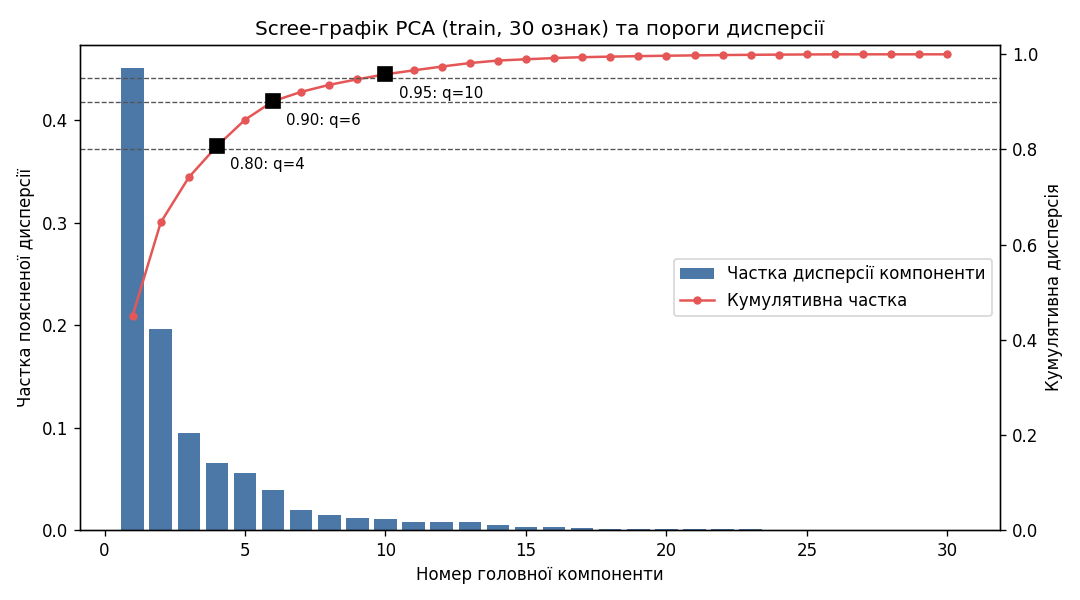

In [7]:
pv = pd.read_csv(RES / "pca_variance.csv")
display(pv.head(12).round(4))
evr = pv.explained_variance_ratio.to_numpy()
print("Σ evr =", round(evr.sum(), 12), "| q для 0.99:", U.choose_n_components(evr, 0.99))
kaiser = int((evr > 1 / len(evr)).sum())
print(f"Критерій Кайзера (власне значення > 1, тобто evr > 1/30 = {1 / 30:.4f}): {kaiser} компонент")
show_fig("01_scree_cumulative.png", 850)

**Висновки.**

* Перші компоненти несуть основну частку дисперсії: PC1 — **45.08 %**, PC2 — **19.58 %**, PC3 — **9.49 %**; разом три компоненти дають **74.15 %**.
  Далі вклад різко падає (PC4 — 6.56 %, PC5 — 5.54 %, PC6 — 3.90 %, PC7 — лише 1.96 %), тож «лікоть» scree-графіка припадає на 3–6 компоненту.
* Кумулятивна дисперсія перетинає пороги: **0.80** — на 4-й компоненті (0.8070), **0.90** — на 6-й (0.9014), **0.95** — на 10-й (0.9580).
  Це не випадково мало: 30 ознак сильно корельовані (радіус, периметр, площа — три способи виміряти розмір), тож ефективна розмірність даних значно менша за 30.
* Незалежний критерій Кайзера (компоненти, чия дисперсія більша за дисперсію однієї стандартизованої ознаки) також дає **6** компонент.
  Він не використовується для вибору (вибір — за правилом конфігурації, розділ 5), але підтверджує, що $q=6$ не суперечить цьому критерію.
* Дисперсії ≥ 99 % потрібно вже 16 компонент: «хвіст» з десятків малих компонент містить шумову й індивідуальну варіацію — саме він
  відсікається PCA і саме він працюватиме в похибці відновлення.

## 5. Вибір робочої розмірності $q$ (завдання 3.6)

`choose_n_components(evr, threshold)` повертає найменше $q$, для якого кумулятивна частка $\ge$ порога (з допуском $10^{-12}$ проти шуму float).
Порівнюємо три пороги за поясненою дисперсією, похибкою відновлення train (середня й 95-й перцентиль), часом підгонки PCA та метрикою наступної задачі —
silhouette K-Means з $K=2$ (seed 42) у відповідному просторі.

,threshold,q,cumulative_variance,recon_mse_mean,recon_mse_p95,silhouette_k2,pca_fit_time_s
0,0.80,4,0.8070,0.1930,0.6206,0.4118,0.0052
1,0.90,6,0.9014,0.0986,0.2647,0.3767,0.0044
2,0.95,10,0.9580,0.0420,0.1116,0.3577,0.0047


Правило з конфігурації: working_threshold = 0.9 -> q = 6
Перевірка: recon_mse_mean = 1 - cumulative_variance: True
Для порівняння: silhouette K=2 у повному 30-вимірному просторі (середнє за 5 seed) = 0.3451


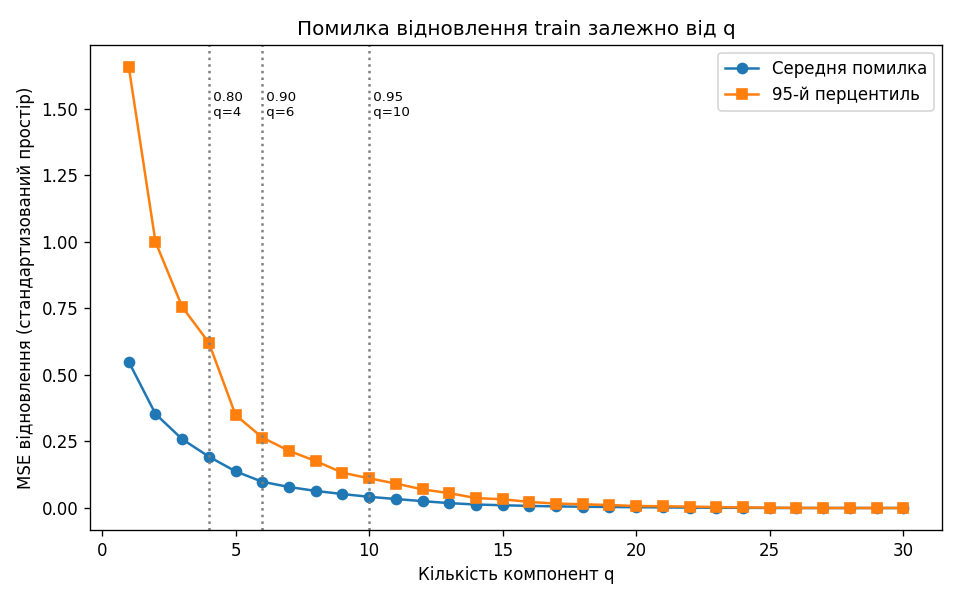


Порядок запису файлів у запуску: pca_dimension_comparison.csv < selected_k.json < external_audit.csv < anomaly_injections.csv


In [8]:
dim = pd.read_csv(RES / "pca_dimension_comparison.csv")
display(dim.round(4))
q_work = U.choose_n_components(evr, cfg["pca"]["working_threshold"])
print(f"Правило з конфігурації: working_threshold = {cfg['pca']['working_threshold']} -> q = {q_work}")
assert q_work == 6 and list(dim.q) == [4, 6, 10]
print("Перевірка: recon_mse_mean = 1 - cumulative_variance:", np.allclose(dim.recon_mse_mean, 1 - dim.cumulative_variance, atol=1e-9))
sil30_k2 = pd.read_csv(RES / "clustering_summary.csv").query("space == 'scaled30' and K == 2").silhouette_mean.iloc[0]
print(f"Для порівняння: silhouette K=2 у повному 30-вимірному просторі (середнє за 5 seed) = {sil30_k2:.4f}")
show_fig("02_reconstruction_error_vs_q.png", 800)

# Порядок створення файлів відображає протокол: q -> K -> аудит (мітки) -> аномалії
order = ["pca_dimension_comparison.csv", "selected_k.json", "external_audit.csv", "anomaly_injections.csv"]
mt = [(f, (RES / f).stat().st_mtime) for f in order]
print("\nПорядок запису файлів у запуску:", " < ".join(f for f, _ in mt))
assert all(mt[i][1] <= mt[i + 1][1] for i in range(len(mt) - 1))

**Висновки та фіксація $q$.**

| Поріг | $q$ | Кумул. дисперсія | MSE відновлення (середнє / p95) | silhouette $K=2$ |
|-------|-----|------------------|-------------------------------|------------------|
| 0.80 | 4 | 0.8070 | 0.1930 / 0.6206 | 0.4118 |
| **0.90** | **6** | **0.9014** | **0.0986 / 0.2647** | **0.3767** |
| 0.95 | 10 | 0.9580 | 0.0420 / 0.1116 | 0.3577 |

* **Робоча розмірність $q = 6$** зафіксована правилом «найменше $q$ з кумулятивною дисперсією $\ge 0.90$», записаним у конфігурації,
  і застосована **до** формування аномалій та до відкриття міток (порядок запису файлів у клітинці вище це підтверджує).
* Середня помилка відновлення (на ознаку) в стандартизованому просторі дорівнює $1-\text{кумулятивна дисперсія}$ (0.1930, 0.0986, 0.0420) — тобто
  ці два стовпці несуть ту саму інформацію; **95-й перцентиль** додає нове: «хвіст» об'єктів, що погано відновлюються, у 2.6–3.2 раза гірший за середнє.
  Він пізніше стане основою порогу детектора (розділ 14).
* **Silhouette зростає, коли $q$ зменшується** (0.4118 для $q=4$, 0.3767 для $q=6$, 0.3577 для $q=10$, 0.3451 для 30 вимірів). Це **не є підставою** обирати
  найменше $q$: у просторі з меншою кількістю вимірів відстані стиснуті й «концентрація відстаней» штучно покращує silhouette; крім того, ця метрика
  вимірює лише відокремленість двох груп, а не те, чи збережено інформацію (при $q=4$ втрачено 19.3 % дисперсії).
  Час підгонки PCA — кілька мілісекунд для всіх варіантів, тож він не є розрізняльним критерієм.
* $q=6$ — компроміс: втрачено < 10 % дисперсії, середня помилка відновлення 0.0986, а простір у 5 разів менший за початковий.
  Поріг 90 % — не універсальний оптимум; у розділі 17 показано (лише як post-hoc діагностику), як чутливі аномалії до цього вибору.

## 6. Візуалізація компонент (завдання 3.7)

Навантаження перших трьох компонент (рядки `components_` — одиничні вектори) та 2D-проєкція train у площині PC1/PC2.

,PC1,PC2,PC3
1,concave_points_mean (+0.259),fractal_dimension_mean (+0.367),texture_se (+0.420)
2,concavity_mean (+0.255),fractal_dimension_se (+0.283),smoothness_worst (-0.274)
3,concave_points_worst (+0.251),fractal_dimension_worst (+0.262),radius_se (+0.273)
4,compactness_mean (+0.240),area_mean (-0.246),smoothness_se (+0.272)
5,concavity_worst (+0.234),radius_mean (-0.242),perimeter_se (+0.266)
6,perimeter_worst (+0.232),compactness_se (+0.235),symmetry_se (+0.262)


PC1: усі 30 навантажень додатні: True | мін/макс |PC1|: 0.004 0.259
Σ навантажень² на компоненту (має бути 1): {'PC1': 1.0, 'PC2': 1.0, 'PC3': 1.0}


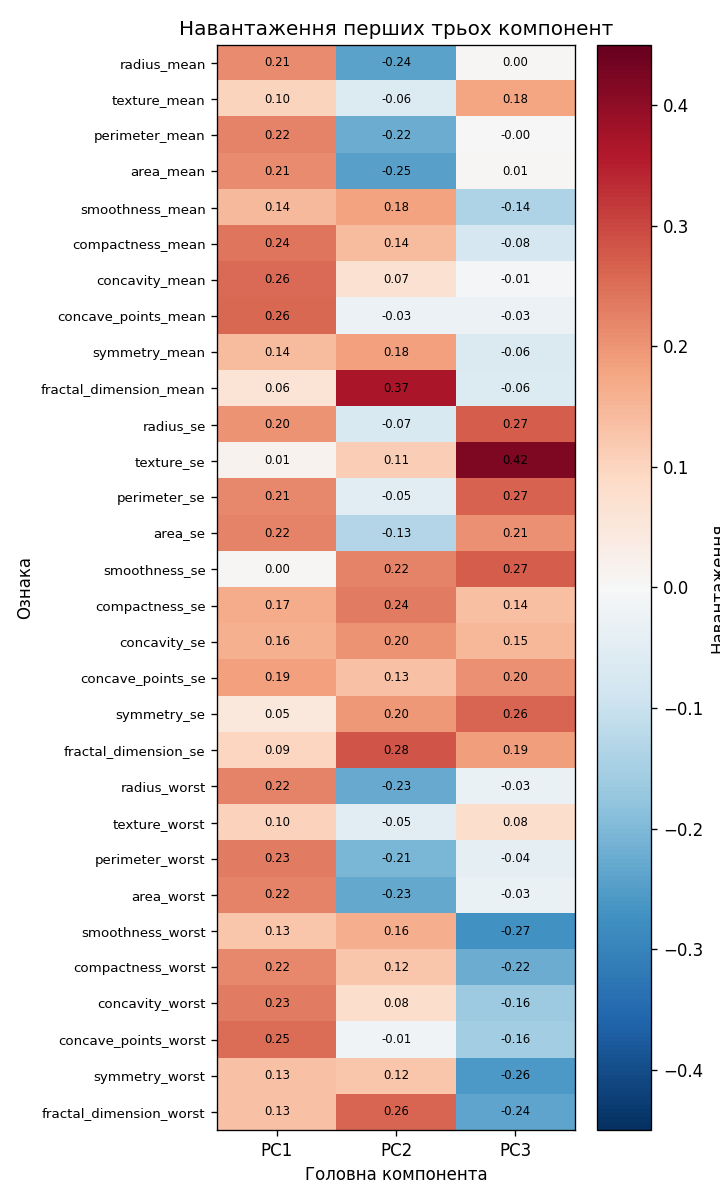

In [9]:
load = pd.read_csv(RES / "pca_loadings.csv", index_col="feature")
tops = {}
for pc in load.columns:
    order_ = load[pc].abs().sort_values(ascending=False).index[:6]
    tops[pc] = [f"{f} ({load.loc[f, pc]:+.3f})" for f in order_]
display(pd.DataFrame(tops, index=range(1, 7)))
print("PC1: усі 30 навантажень додатні:", bool((load.PC1 > 0).all()),
      "| мін/макс |PC1|:", round(load.PC1.min(), 3), round(load.PC1.max(), 3))
print("Σ навантажень² на компоненту (має бути 1):", (load ** 2).sum().round(6).to_dict())
show_fig("03_pca_loadings.png", 560)

PC1+PC2 = 64.66 % дисперсії; решта 35.34 % (PC3..PC30) на рисунку не видна; PC3..PC6 разом = 25.49 %
Silhouette тих самих міток 6D-кластеризації: у 6D = 0.3767, у площині PC1/PC2 = 0.5076
ARI(K-Means у 6D, K-Means лише в 2D) = 0.9823; об'єктів з іншою міткою (після узгодження): 2 з 455


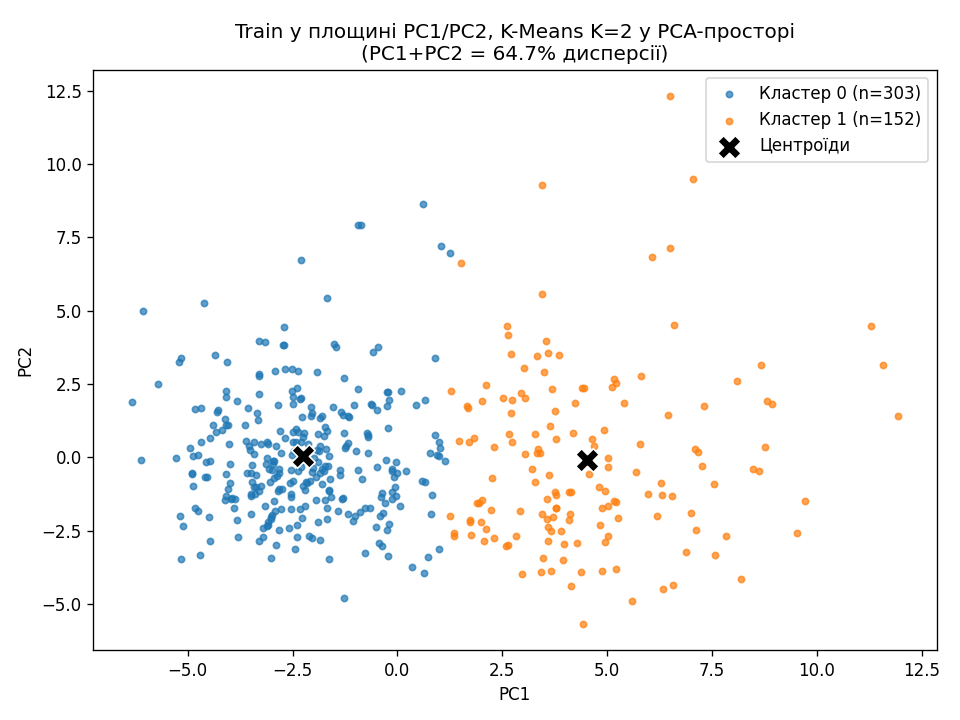

In [10]:
pca_full = U.fit_pca(Xs_tr, Xs_tr.shape[1])
pca6 = U.fit_pca(Xs_tr, q_work)
Z_tr = pca6.transform(Xs_tr)
ref6 = U.fit_reference_kmeans(Z_tr, 2, 42, cfg["kmeans"]["n_init"])
lab6 = ref6.labels_

evr12 = float(evr[0] + evr[1])
print(f"PC1+PC2 = {100 * evr12:.2f} % дисперсії; решта {100 * (1 - evr12):.2f} % (PC3..PC30) на рисунку не видна; PC3..PC6 разом = {100 * evr[2:6].sum():.2f} %")
Z2 = Z_tr[:, :2]
km2 = KMeans(n_clusters=2, n_init=cfg["kmeans"]["n_init"], random_state=42).fit(Z2)
print(f"Silhouette тих самих міток 6D-кластеризації: у 6D = {silhouette_score(Z_tr, lab6):.4f}, у площині PC1/PC2 = {silhouette_score(Z2, lab6):.4f}")
print(f"ARI(K-Means у 6D, K-Means лише в 2D) = {adjusted_rand_score(lab6, km2.labels_):.4f}; "
      f"об'єктів з іншою міткою (після узгодження): {int((U.align_cluster_labels(lab6, km2.labels_) != lab6).sum())} з {len(lab6)}")
show_fig("04_pca_2d_projection.png", 700)

**Висновки.**

* **PC1** (45.08 %) — майже «загальний фактор»: усі 30 навантажень додатні. Найбільші внески — ознаки **форми та вираженості дефектів контуру**
  (`concave_points_mean` 0.259, `concavity_mean` 0.255, `compactness_mean` 0.240) та розмірні ознаки (`perimeter_worst`, `area_worst`, `radius_worst` ≈ 0.22–0.23). Тобто PC1 — вісь «великі й нерівні ядра».
* **PC2** (19.58 %) протиставляє **фрактальну розмірність / `*_se` ознаки** (`fractal_dimension_mean` +0.367, `fractal_dimension_se` +0.283, `fractal_dimension_worst` +0.262)
  **розмірним ознакам** (`area_mean` −0.246, `radius_mean` −0.242): це вісь «складність межі при фіксованому розмірі», ортогональна до PC1.
* **PC3** (9.49 %) визначають ознаки мінливості текстури й розміру (`texture_se` +0.420, `radius_se` +0.273, `smoothness_se` +0.272) — «неоднорідність», а не середній розмір.
* **Що показує 2D-рисунок і чого він не замінює.** PC1+PC2 = **64.66 %** дисперсії; **35.34 %** лишається поза площиною, зокрема PC3–PC6 (25.5 %), які входять у робочий 6-вимірний простір.
  Алгоритми (K-Means, Isolation Forest, похибка відновлення) працюють у 6D (90.14 %), а рисунок — лише проєкція: на ньому можуть виглядати «змішаними» групи,
  розділені в PC3–PC6, і навпаки. Тому оцінювання кластерів (silhouette, ARI, стабільність) і аномалій виконується в **робочому просторі**, а не за візуальним враженням.
  Числова ілюстрація: ті самі мітки 6D-кластеризації мають silhouette **0.3767** у 6D, але **0.5076** у площині PC1/PC2 — картинка виглядає помітно «чіткішою», ніж є насправді
  (саме ця оптична ілюзія й створює хибне відчуття надійності). Для $K=2$ проєкція все ж відносно вірна: K-Means, запущений лише на PC1/PC2, відрізняється від 6D-розбиття всього у 2 з 455 об'єктів (ARI 0.9823),
  але така відповідність — властивість цих даних і цього $K$, її треба перевіряти, а не припускати.

## 7–8. K-Means у двох просторах за однаковим протоколом (завдання 3.8–3.9)

Протокол ідентичний у **scaled30** (30 масштабованих ознак) і **pca6** (6 компонент): $K \in \{2,\dots,10\}$, 5 seeds (11, 23, 42, 67, 101), `n_init = 10`;
для кожного запуску (K, seed) збережено inertia, silhouette, Davies–Bouldin, Calinski–Harabasz, час. Splits, сітка $K$ і seeds не змінювались.

clustering_runs.csv: (90, 8) | рядків на простір: {'pca6': 45, 'scaled30': 45} | колонки: ['space', 'K', 'seed', 'inertia', 'silhouette', 'davies_bouldin', 'calinski_harabasz', 'fit_time_s']

--- scaled30 (середнє по 5 seed; ari/nmi — середні попарні між seed) ---


,K,inertia_mean,silhouette_mean,silhouette_std,davies_bouldin_mean,calinski_harabasz_mean,ari_mean,nmi_mean
0,2,9004.4930,0.3451,0.0005,1.2566,233.7072,0.9947,0.9868
1,3,7960.9078,0.3199,0.0050,1.5430,161.5061,0.9211,0.8615
2,4,7229.9787,0.1950,0.0067,1.8373,133.4919,0.9025,0.8753
3,5,6679.7890,0.1729,0.0009,1.7782,117.3924,0.8469,0.8286
4,6,6184.5778,0.1709,0.0062,1.6353,108.4003,0.8070,0.8117
5,7,5819.9732,0.1487,0.0066,1.6475,100.4582,0.6974,0.7712
6,8,5542.2128,0.1408,0.0037,1.5904,93.4178,0.6418,0.7561
7,9,5352.8881,0.1325,0.0057,1.5953,86.4150,0.6161,0.7298
8,10,5195.0523,0.1206,0.0040,1.6912,80.4717,0.5160,0.6874



--- pca6 (середнє по 5 seed; ari/nmi — середні попарні між seed) ---


,K,inertia_mean,silhouette_mean,silhouette_std,davies_bouldin_mean,calinski_harabasz_mean,ari_mean,nmi_mean
0,2,7660.8883,0.3767,0.0000,1.1483,274.6009,1.0000,1.0000
1,3,6620.2050,0.3523,0.0047,1.3944,194.0598,0.9737,0.9457
2,4,5890.9642,0.2148,0.0083,1.6603,163.6764,0.8497,0.8355
3,5,5351.3803,0.2043,0.0042,1.5575,146.1789,0.8837,0.8357
4,6,4871.3329,0.2046,0.0021,1.4400,137.0324,0.8659,0.8585
5,7,4497.5147,0.1924,0.0050,1.4470,129.6148,0.8244,0.8488
6,8,4240.6395,0.1806,0.0023,1.4017,121.4331,0.8221,0.8515
7,9,4061.5490,0.1680,0.0064,1.4109,113.1508,0.5582,0.7057
8,10,3902.2210,0.1620,0.0048,1.4357,106.4705,0.6959,0.7752


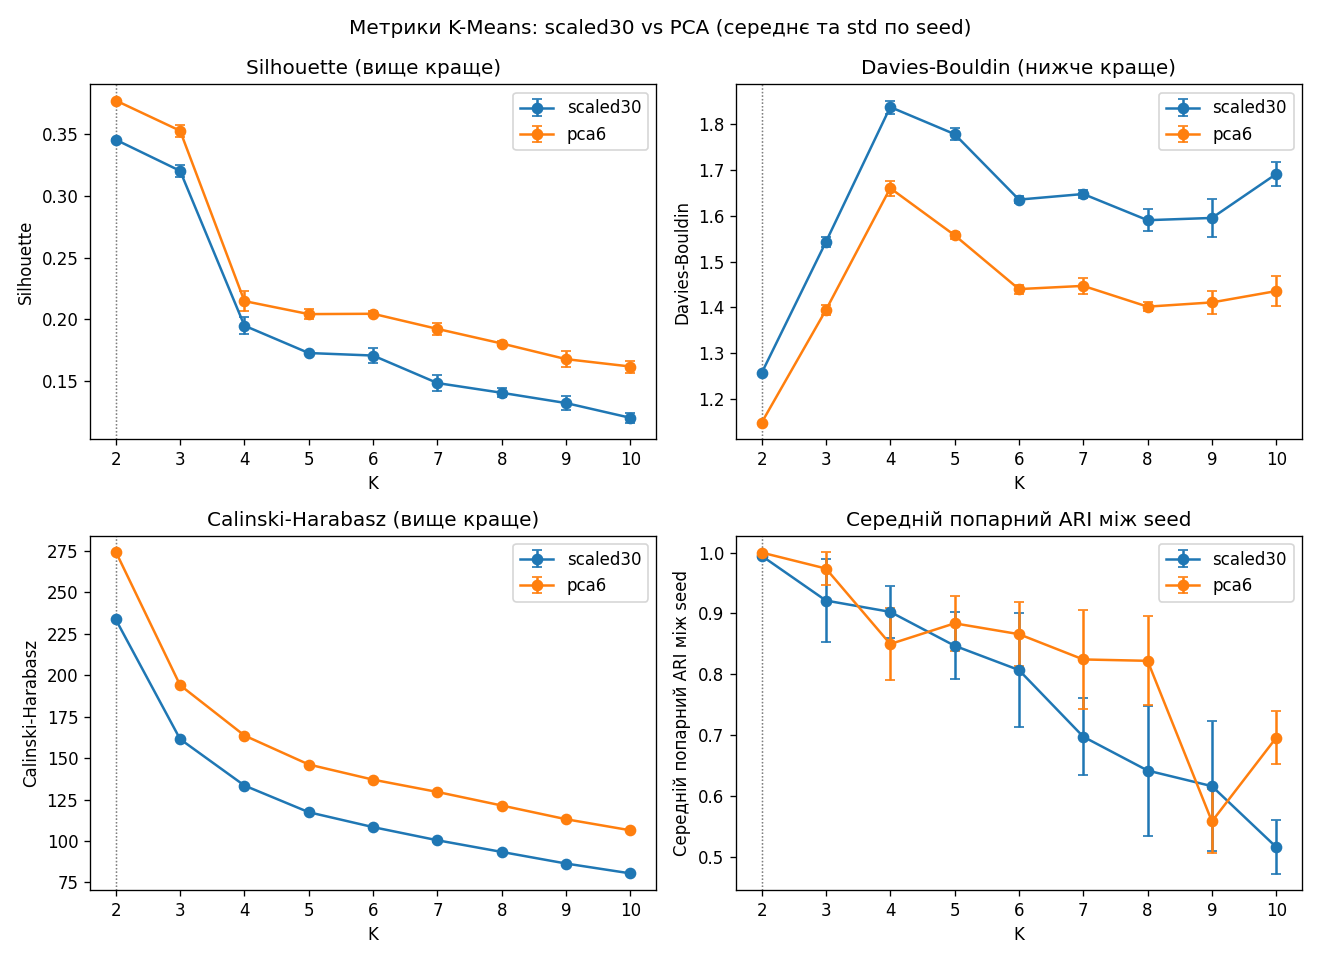

In [11]:
runs = pd.read_csv(RES / "clustering_runs.csv")
summ = pd.read_csv(RES / "clustering_summary.csv")
print("clustering_runs.csv:", runs.shape, "| рядків на простір:", runs.groupby("space").size().to_dict(),
      "| колонки:", list(runs.columns))
cols = ["K", "inertia_mean", "silhouette_mean", "silhouette_std", "davies_bouldin_mean", "calinski_harabasz_mean", "ari_mean", "nmi_mean"]
for sp in summ.space.unique():
    print(f"\n--- {sp} (середнє по 5 seed; ari/nmi — середні попарні між seed) ---")
    display(summ[summ.space == sp][cols].round(4).reset_index(drop=True))
show_fig("05_clustering_metrics.png", 900)

In [12]:
sel = json.loads((RES / "selected_k.json").read_text(encoding="utf-8"))
display(pd.DataFrame(sel).T)
for sp in summ.space.unique():
    s = summ[summ.space == sp].sort_values("silhouette_mean", ascending=False)
    best, second = s.iloc[0], s.iloc[1]
    print(f"{sp}: найкращий silhouette K={int(best.K)} ({best.silhouette_mean:.4f}); другий K={int(second.K)} ({second.silhouette_mean:.4f}); "
          f"різниця {best.silhouette_mean - second.silhouette_mean:.4f} {'>=' if best.silhouette_mean - second.silhouette_mean >= 0.01 else '<'} practical_tie = 0.01")

# Еталонні моделі (seed 42) та порівняння двох просторів
ref30 = U.fit_reference_kmeans(Xs_tr, 2, 42, cfg["kmeans"]["n_init"])
lab30 = ref30.labels_
st30 = pd.read_csv(RES / "object_stability_scaled30.csv")
st6 = pd.read_csv(RES / "object_stability_pca6.csv")
assert np.array_equal(st30.reference_cluster, lab30) and np.array_equal(st6.reference_cluster, lab6)
print(f"\nInertia K=2: scaled30 = {ref30.inertia_:.1f}, pca6 = {ref6.inertia_:.1f} (відношення {ref6.inertia_ / ref30.inertia_:.3f}); "
      f"частка дисперсії, збереженої PCA = {evr[:q_work].sum():.4f}")
print(f"Розбиття у двох просторах: ARI(scaled30, pca6) = {adjusted_rand_score(lab30, lab6):.4f}; "
      f"розбіжних об'єктів після узгодження міток: {int((U.align_cluster_labels(lab30, lab6) != lab30).sum())} з {len(lab6)}")

,selected_k,silhouette_mean,ari_mean,best_silhouette_k,best_silhouette,tie_candidates,practical_tie
scaled30,2,0.345052,0.994665,2,0.345052,[2],0.01
pca6,2,0.376695,1.0,2,0.376695,[2],0.01


scaled30: найкращий silhouette K=2 (0.3451); другий K=3 (0.3199); різниця 0.0251 >= practical_tie = 0.01
pca6: найкращий silhouette K=2 (0.3767); другий K=3 (0.3523); різниця 0.0244 >= practical_tie = 0.01

Inertia K=2: scaled30 = 9004.6, pca6 = 7660.9 (відношення 0.851); частка дисперсії, збереженої PCA = 0.9014
Розбиття у двох просторах: ARI(scaled30, pca6) = 0.9911; розбіжних об'єктів після узгодження міток: 1 з 455


**Висновки.**

* **Застосування правила вибору $K$** (максимум середнього silhouette; якщо відставання < 0.01 — вищий середній попарний ARI, потім менший $K$).
  У **scaled30** найкращий $K=2$ (silhouette 0.3451), другий — $K=3$ (0.3199): різниця **0.0251 ≥ 0.01**, тож «практичної рівності» немає, `tie_candidates = [2]`.
  У **pca6** — $K=2$ (0.3767) проти $K=3$ (0.3523): різниця **0.0244 ≥ 0.01**, знову `tie_candidates = [2]`. **Обрано $K=2$ в обох просторах**, правило застосовано окремо до кожного.
* Для $K \ge 4$ silhouette різко падає (0.195 → 0.121 у scaled30; 0.215 → 0.162 у pca6), Davies–Bouldin зростає, а ARI між seed знижується до 0.52 (scaled30, $K=10$) і 0.56 (pca6, $K=9$):
  такі розбиття нестійкі до ініціалізації. Є локальний «горбик» на $K=3$ (silhouette 0.32 / 0.35), але він поступається $K=2$.
* **PCA-простір не гірший за початковий за внутрішніми метриками:** silhouette 0.3767 проти 0.3451, Davies–Bouldin 1.148 проти 1.257 (нижче краще), Calinski–Harabasz 274.6 проти 233.7;
  ARI між seeds для $K=2$ — **1.0000** у pca6 проти 0.9947 у scaled30. Але **абсолютні значення метрик у просторах різної розмірності порівнювати слід обережно**:
  silhouette і Calinski–Harabasz залежать від розмірності.
* **Inertia не можна порівнювати між просторами:** вона вимірюється у різних координатах (30 vs 6 вимірів). Для $K=2$ inertia у pca6 (7660.9) на 14.9 % менша, ніж у scaled30 (9004.6) — але це лише наслідок
  того, що PCA відкинула 24 компоненти (9.86 % загальної дисперсії), а не ознака «кращої» кластеризації. Порівнювати треба безрозмірні метрики й стабільність, а не inertia.
* **Розбиття майже збігаються:** ARI між мітками двох просторів дорівнює **0.9911**, а після узгодження міток розрізняється лише **1 з 455** об'єкта: редукція до 6 вимірів не змінила структуру, яку знаходить K-Means.

## 9. Стійкість кластеризації (завдання 3.10)

Два рівні: (а) **seed-рівень** — середній попарний ARI/NMI між 5 повними прогонами; (б) **об'єктний рівень** — 20 прогонів K-Means на випадкових 90 %-підвибірках train
(410 з 455 об'єктів; кожен прогін передбачає мітки **всіх** train-об'єктів), мітки узгоджуються з еталоном (seed 42, повний train) угорським алгоритмом;
стабільність об'єкта = частка прогонів із такою ж узгодженою міткою. Поріг нестабільності — 0.8.

,K,seed_ari_mean,seed_nmi_mean,run_ari_vs_reference_mean,mean_object_stability,n_below_threshold,n_below_1,n_objects,subsample_size
scaled30,2.0,0.994665,0.98683,0.984044,0.996044,4.0,8.0,455.0,410.0
pca6,2.0,1.000000,1.00000,0.987186,0.996813,2.0,9.0,455.0,410.0



=== 10 найменш стабільних об'єктів: scaled30 (K=2) ===


,id,reference_cluster,stability,dist_own_centroid,margin_to_other
0,86,0,0.35,4.4582,0.0091
1,318,1,0.60,8.4633,0.0574
2,207,1,0.75,5.1142,0.0650
3,376,0,0.75,9.1999,0.1292
4,81,0,0.90,4.7328,0.2135
5,39,1,0.95,4.8599,0.1062
6,99,1,0.95,3.8745,0.1282
7,435,1,0.95,4.5879,0.1333
8,255,1,1.00,3.7549,0.1955
9,176,1,1.00,9.4423,0.2380


scaled30: стабільність < 1: 8; < 0.8: 4; Spearman(stability, margin_to_other) = 0.228; медіана margin: нестабільні(<1) 0.117 vs стабільні(=1) 4.090



=== 10 найменш стабільних об'єктів: pca6 (K=2) ===


,id,reference_cluster,stability,dist_own_centroid,margin_to_other
0,318,0,0.55,8.1087,0.0648
1,86,0,0.70,4.0099,0.0337
2,376,1,0.85,8.8276,0.1332
3,207,0,0.90,4.9633,0.1054
4,39,0,0.90,4.6340,0.1269
5,435,0,0.90,4.5018,0.1536
6,99,0,0.90,3.6083,0.1643
7,255,0,0.90,3.6012,0.2163
8,81,1,0.95,4.5683,0.2183
9,119,1,1.00,6.6192,0.2629


pca6: стабільність < 1: 9; < 0.8: 2; Spearman(stability, margin_to_other) = 0.241; медіана margin: нестабільні(<1) 0.133 vs стабільні(=1) 4.314

Об'єкти зі stability < 1 в обох просторах: [39, 81, 86, 99, 207, 318, 376, 435] (8 з 8 та 9)
Об'єкти зі stability < 0.8: scaled30 [86, 207, 318, 376] | pca6 [86, 318]


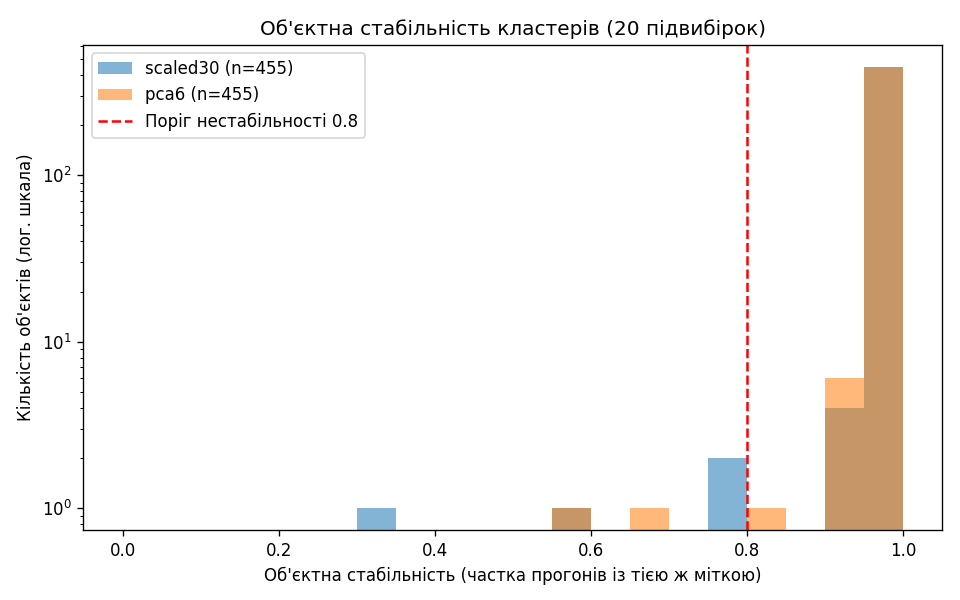

In [13]:
stab = pd.DataFrame(json.loads((RES / "stability_summary.json").read_text(encoding="utf-8"))).T
display(stab)
for sp, tab in (("scaled30", st30), ("pca6", st6)):
    print(f"\n=== 10 найменш стабільних об'єктів: {sp} (K=2) ===")
    display(tab.sort_values(["stability", "margin_to_other"]).head(10).round(4).reset_index(drop=True))
    rho = spearmanr(tab.stability, tab.margin_to_other)
    print(f"{sp}: стабільність < 1: {int((tab.stability < 1).sum())}; < 0.8: {int((tab.stability < 0.8).sum())}; "
          f"Spearman(stability, margin_to_other) = {rho.statistic:.3f}; "
          f"медіана margin: нестабільні(<1) {tab.loc[tab.stability < 1, 'margin_to_other'].median():.3f} vs стабільні(=1) {tab.loc[tab.stability == 1, 'margin_to_other'].median():.3f}")
u30, u6 = set(st30.loc[st30.stability < 1, "id"]), set(st6.loc[st6.stability < 1, "id"])
print("\nОб'єкти зі stability < 1 в обох просторах:", sorted(u30 & u6), f"({len(u30 & u6)} з {len(u30)} та {len(u6)})")
print("Об'єкти зі stability < 0.8: scaled30", sorted(st30.loc[st30.stability < 0.8, 'id']), "| pca6", sorted(st6.loc[st6.stability < 0.8, 'id']))
show_fig("06_object_stability.png", 700)

**Висновки.**

| Простір | ARI між seeds | NMI між seeds | ARI підвибірок vs еталон | середня стабільність | об'єктів < 0.8 | об'єктів < 1 |
|---------|--------------|---------------|-------------------------|---------------------|---------------|--------------|
| scaled30 | 0.9947 | 0.9868 | 0.9840 | 0.9960 | **4** | 8 |
| pca6 | 1.0000 | 1.0000 | 0.9872 | 0.9968 | **2** | 9 |

* Розбиття **дуже стійке**: за зміни seed ARI ≈ 1, а 20 підвибірок по 90 % відтворюють еталон із ARI 0.984–0.987. Нестабільних (< 0.8) об'єктів — 4 з 455 у scaled30 і 2 з 455 у pca6 (≤ 0.9 %).
* Нестабільні об'єкти — **граничні**. Серед 10 найменш стабільних кожного простору відстань до найближчого *іншого* центроїда майже дорівнює відстані до власного:
  `margin_to_other` у найменш стабільних — 0.0091 (id 86, стабільність 0.35, scaled30), 0.0574 (id 318, 0.60), 0.0337 (id 86, 0.70, pca6), 0.0648 (id 318, 0.55, pca6); медіана `margin_to_other` для об'єктів зі стабільністю < 1 —
  0.117 (scaled30) і 0.133 (pca6) проти 4.090 і 4.314 для повністю стабільних, тобто **у 30–35 разів менша**. Це об'єкти біля межі між двома кластерами, які «перескакують» залежно від підвибірки.
  (Кореляція Спірмена між стабільністю і запасом лише ≈ 0.23–0.24, бо стабільність «насичується» на 1.0 для більшості об'єктів.)
* Об'єкти **86, 318, 207, 376, 39, 99, 435, 81** з'являються у списках обох просторів — нестабільність є властивістю самих об'єктів, а не артефактом одного простору.
  Об'єкти 318 і 376 до того ж **далекі від центроїда** (`dist_own_centroid` ≈ 8–9 проти ≈ 3.5–5 у решти списку): це відхилення/викиди, що лежать між кластерами, — природні кандидати на ручну перевірку.
* Відмінність у кількості нестабільних об'єктів (4 vs 2) — це різниця в 2 об'єкти; її не варто перебільшувати, але вона не суперечить тому,
  що в редукованому просторі кластеризація щонайменше не менш стабільна. Усі 8 об'єктів зі stability < 1 у scaled30 є й серед 9 у pca6.
* Обмеження методу: прогін на підвибірці передбачає мітки **всіх** train-об'єктів, зокрема й тих 90 %, на яких він навчався, тому оцінка стабільності трохи оптимістична.
* Висока стійкість $K=2$ не доводить, що кластери «реальні»: K-Means знаходить два стабільні півпростори майже за будь-якої двомодальної структури — зміст груп перевіряє зовнішній аудит.

## 10. Зовнішній аудит (завдання 3.11)

**Мітки діагнозу відкриваються лише тут — після фіксації $q=6$ і $K=2$ в обох просторах.** Для train — мітки, отримані K-Means у кожному просторі; для test (чистий, без аномалій) —
передбачення еталонної моделі. Таблиця складу кластерів: кластер × діагноз (`0 = malignant`, `1 = benign`; номери кластерів — **умовні ідентифікатори**).

,space,part,K,n,ari,nmi,homogeneity,completeness
0,scaled30,train,2,455,0.6986,0.5845,0.5747,0.5948
1,scaled30,test_clean,2,114,0.7354,0.6188,0.6141,0.6236
2,pca6,train,2,455,0.6911,0.5773,0.5669,0.5881
3,pca6,test_clean,2,114,0.7354,0.6188,0.6141,0.6236


,space,part,cluster,malignant,benign,size,malignant_share
0,scaled30,train,0,143,10,153,0.9346
1,scaled30,train,1,27,275,302,0.0894
2,scaled30,test_clean,0,37,3,40,0.9250
3,scaled30,test_clean,1,5,69,74,0.0676
4,pca6,train,0,28,275,303,0.0924
5,pca6,train,1,142,10,152,0.9342
6,pca6,test_clean,0,5,69,74,0.0676
7,pca6,test_clean,1,37,3,40,0.9250


scaled30  train     : об'єктів, що опинилися не в «своєму» кластері більшості: 37 з 455 = 8.1 %
scaled30  test_clean: об'єктів, що опинилися не в «своєму» кластері більшості: 8 з 114 = 7.0 %
pca6      train     : об'єктів, що опинилися не в «своєму» кластері більшості: 38 з 455 = 8.4 %
pca6      test_clean: об'єктів, що опинилися не в «своєму» кластері більшості: 8 з 114 = 7.0 %


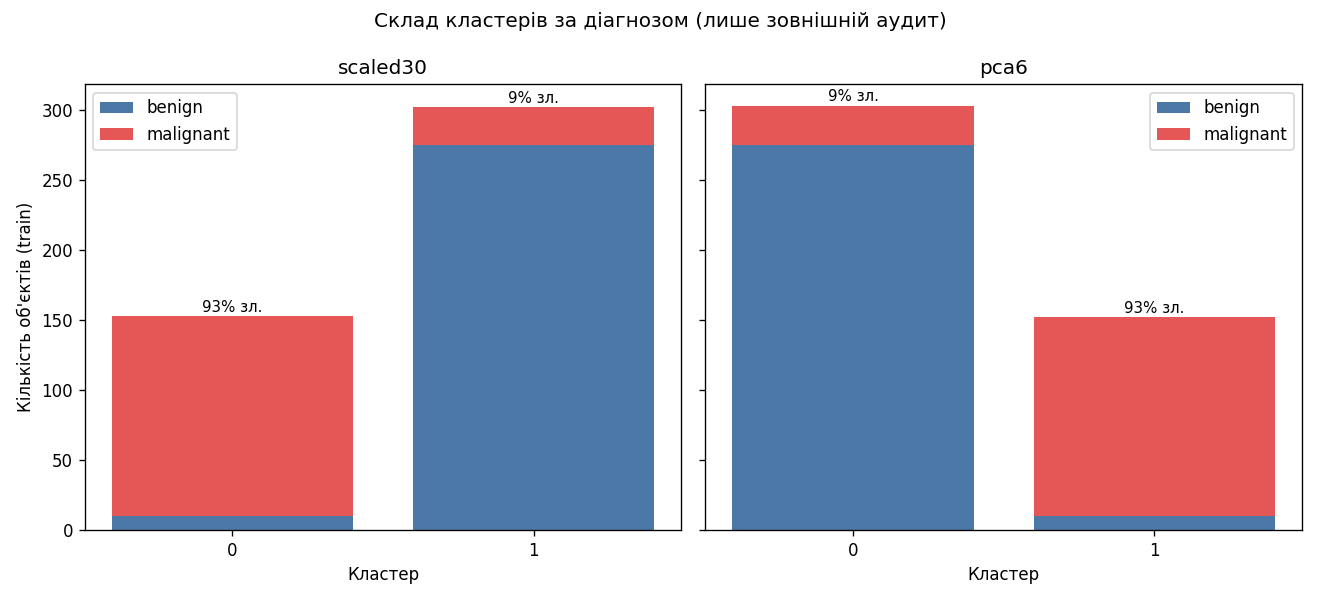

In [14]:
audit = pd.read_csv(RES / "external_audit.csv")
comp = pd.read_csv(RES / "cluster_composition.csv")
display(audit.round(4))
display(comp.round(4))
for (sp, part), g in comp.groupby(["space", "part"], sort=False):
    wrong = int(np.minimum(g.malignant, g.benign).sum())
    print(f"{sp:9s} {part:10s}: об'єктів, що опинилися не в «своєму» кластері більшості: {wrong} з {int(g['size'].sum())} = {100 * wrong / g['size'].sum():.1f} %")
show_fig("07_cluster_composition.png", 700)

**Висновки.**

* Кластери **корелюють із діагнозом, але не збігаються з ним.** Train, scaled30: ARI **0.6986**, NMI 0.5845, homogeneity 0.5747, completeness 0.5948;
  pca6: ARI 0.6911, NMI 0.5773 (різниця 0.0075 — у межах шуму, не підстава віддати перевагу одному простору). На чистому test обидва простори дають **однакові** ARI 0.7354 і NMI 0.6188
  (розбиття test у двох просторах збігається).
* Склад кластерів (train, scaled30): кластер 0 — 143 злоякісних і 10 доброякісних (частка злоякісних 93.5 %), кластер 1 — 27 злоякісних і 275 доброякісних (8.9 %).
  У pca6 ті самі групи, але **з іншими номерами**: кластер 1 — 142 / 10 (93.4 %), кластер 0 — 28 / 275 (9.2 %). **Номер кластера не має змісту** (у першому просторі «0» — переважно злоякісні, у другому — доброякісні),
  тому порівнювати запуски можна лише через ARI/NMI або узгодження міток.
* Не у «своєму» кластері опиняється **8.1 %** (37 з 455, scaled30) і **8.4 %** (38 з 455, pca6) train-об'єктів, на test — **7.0 %** (8 з 114). Тобто приблизно кожен
  12-й об'єкт перебуває по інший бік від діагностичної межі: $K=2$ — це **не** «діагноз», а непідконтрольне групування за розміром/нерегулярністю ядра, яке сильно (але не ідеально) з діагнозом пов'язане.
* Аудит **не змінював** вибір $q$ чи $K$ (вони зафіксовані раніше) — у цьому полягає розділення «вибір параметрів / зовнішній аудит / фінальна перевірка».

## 11. Формування контрольованих аномалій (завдання 3.12)

Чотири предметно осмислені перетворення **сирих** значень test (до `log1p` і скейлера); train не змінюється. Для кожного типу — 6 різних test-об'єктів (разом 24 з 114),
вибраних випадково із seed 42. Зберігаються `id`, тип і параметри (діагноз у таблицю **не** потрапляє).

In [15]:
inj = pd.read_csv(RES / "anomaly_injections.csv")
inj["params"] = inj["params"].astype(str)
summary = inj.groupby("kind", sort=False).agg(count=("id", "size"), params=("params", "first"),
                                              ids=("id", lambda s: sorted(s))).reset_index()
display(summary)

batch = U.inject_controlled_anomalies(data.X_test, data.id_test, cfg)
batch2 = U.inject_controlled_anomalies(data.X_test, data.id_test, cfg)
print("Відтворення з config: id/тип збігаються з anomaly_injections.csv:",
      sorted(map(tuple, batch.params_table[["id", "kind"]].values.tolist())) == sorted(map(tuple, inj[["id", "kind"]].values.tolist())))
print("Детермінованість (два виклики з тим самим seed):", bool(batch.X.equals(batch2.X) and np.array_equal(batch.kind, batch2.kind)))
print("Вхідний data.X_test не змінено:", bool(not batch.X.equals(data.X_test) and data.X_test.shape == batch.X.shape))
print("Позначено аномалій:", int(batch.is_anomaly.sum()), "з", len(batch.kind), "| train-кадр не передавався у генератор взагалі")

# приклад «до / після» для одного об'єкта кожного типу
show_cols = {"calibration_scale": ["radius_mean", "perimeter_mean", "area_mean", "area_worst"],
             "geometry_break": ["radius_mean", "perimeter_mean", "area_mean", "area_worst"],
             "worst_mean_swap": ["radius_mean", "radius_worst", "concavity_mean", "concavity_worst"],
             "texture_noise": ["texture_mean", "smoothness_mean", "symmetry_mean", "fractal_dimension_mean"]}
for kind_, cols_ in show_cols.items():
    oid = int(inj.loc[inj.kind == kind_, "id"].iloc[0])
    pos = list(data.id_test).index(oid)
    ex = pd.DataFrame({"до": data.X_test.iloc[pos][cols_], "після": batch.X.iloc[pos][cols_]})
    ex["відношення"] = ex["після"] / ex["до"]
    print(f"\n{kind_}, id = {oid}")
    display(ex.round(4))

,kind,count,params,ids
0,calibration_scale,6,"{""factor"": 1.6}","[296, 359, 428, 501, 507, 519]"
1,geometry_break,6,"{""area_factor"": 0.4}","[73, 150, 284, 321, 434, 439]"
2,worst_mean_swap,6,{},"[70, 247, 298, 375, 408, 537]"
3,texture_noise,6,"{""sigma"": 0.5, ""n_cells"": 72}","[95, 140, 295, 488, 535, 564]"


Відтворення з config: id/тип збігаються з anomaly_injections.csv:

 True
Детермінованість (два виклики з тим самим seed): True
Вхідний data.X_test не змінено: True
Позначено аномалій: 24 з 114 | train-кадр не передавався у генератор взагалі

calibration_scale, id = 507


,до,після,відношення
radius_mean,11.06,17.696,1.60
perimeter_mean,71.25,114.000,1.60
area_mean,366.50,938.240,2.56
area_worst,411.10,1052.416,2.56



geometry_break, id = 150


,до,після,відношення
radius_mean,13.00,13.00,1.0
perimeter_mean,83.51,83.51,1.0
area_mean,519.40,207.76,0.4
area_worst,616.70,246.68,0.4



worst_mean_swap, id = 70


,до,після,відношення
radius_mean,18.9400,24.8600,1.3126
radius_worst,24.8600,18.9400,0.7619
concavity_mean,0.1080,0.2687,2.4880
concavity_worst,0.2687,0.1080,0.4019



texture_noise, id = 564


,до,після,відношення
texture_mean,22.3900,18.0736,0.8072
smoothness_mean,0.1110,0.1333,1.2005
symmetry_mean,0.1726,0.5036,2.9178
fractal_dimension_mean,0.0562,0.0374,0.6657


**Предметний зміст перетворень.**

| Тип | Що робимо з сирими значеннями | Яку реальну проблему моделює |
|-----|------------------------------|------------------------------|
| `calibration_scale` (factor 1.6) | `radius_*`, `perimeter_*` × 1.6, `area_*` × 1.6² = 2.56 — **узгоджене** збільшення | помилка калібрування масштабу зображення (пікселі → мкм): усі розмірні ознаки змінюються разом і зберігають взаємні співвідношення геометрії |
| `geometry_break` (area_factor 0.4) | `area_mean`, `area_worst` × 0.4; радіус і периметр без змін | **фізично неузгоджений** запис: площа не відповідає радіусу ($\pi r^2$) — збій обчислення ознаки або помилка при об'єднанні таблиць |
| `worst_mean_swap` | для всіх 10 базових ознак міняємо місцями `<f>_mean` і `<f>_worst` | перестановка колонок / помилка схеми даних: значення «найгірших» точок записано як середні й навпаки |
| `texture_noise` (σ = 0.5) | 12 колонок (`texture_*`, `smoothness_*`, `symmetry_*`, `fractal_dimension_*`) × $e^{N(0,\,0.5^2)}$ для кожної клітинки (72 клітинки на 6 об'єктів) | шумові спотворення якості знімка/сегментації, що торкаються текстурних ознак, не чіпаючи розмір |

Перші дві аномалії порушують **кореляційну структуру** розмірних ознак (особливо друга); третя — структуру між агрегатами; четверта — випадкові викиди в окремих ознаках.
Передбачуваний наслідок: детектор, що «знає» кореляційну структуру (PCA-відновлення), має бачити перші три типи, а Isolation Forest у початкових координатах — переважно «екстремальні» значення.
Це **гіпотеза**, яку перевіряють наступні розділи; вона не використовується для налаштування порогів.

## 12. Isolation Forest у двох просторах (завдання 3.13)

Однаково налаштований `IsolationForest` (300 дерев, `max_samples="auto"`, `contamination="auto"`, `random_state=42`) навчається на масштабованому train (30 вимірів)
і на PCA(train) (6 вимірів). `score_samples` у sklearn більший для **нормальних** об'єктів, тому використовується $\text{score} = -\text{score\_samples}$ — більше значення означає більшу аномальність.
Також перераховуємо все в notebook (з тих самих функцій модуля) і звіряємо з файлами — це перевірка відтворюваності.

In [16]:
Xs_te = prep.transform(batch.X)                  # test з внесеними аномаліями
Z_te = pca6.transform(Xs_te)
Z_te_clean = pca6.transform(Xs_te_clean)

det = U.fit_anomaly_detectors(Xs_tr, Z_tr, cfg, pca6)
sc_tr = U.score_anomalies(det, Xs_tr, Z_tr, ids=data.id_train)
sc_te = U.score_anomalies(det, Xs_te, Z_te, ids=data.id_test)
sc_te_clean = U.score_anomalies(det, Xs_te_clean, Z_te_clean, ids=data.id_test)
y_an = batch.is_anomaly
y_arr = np.asarray(y_an, dtype=bool)
kind = batch.kind

print("Параметри IF30:", {k: v for k, v in det.if30.get_params().items() if k in ("n_estimators", "max_samples", "contamination", "random_state")})
print("Параметри IFPCA:", {k: v for k, v in det.ifpca.get_params().items() if k in ("n_estimators", "max_samples", "contamination", "random_state")})
print("Орієнтація: Spearman(score_if30, decision_function) на train =",
      round(float(spearmanr(sc_tr.score_if30, det.if30.decision_function(Xs_tr)).statistic), 4),
      "| IFPCA:", round(float(spearmanr(sc_tr.score_ifpca, det.ifpca.decision_function(Z_tr)).statistic), 4), "(-1 => більше скор = аномальніше)")

metrics = pd.read_csv(RES / "anomaly_metrics.csv")
metrics_re = U.evaluate_anomalies(sc_te, y_an)
pd.testing.assert_frame_equal(metrics_re, metrics.drop(columns="threshold"), check_exact=False, atol=1e-9, check_dtype=False)
print("Незалежний перерахунок у notebook збігається з results/anomaly_metrics.csv (assert_frame_equal, atol=1e-9).")
for d in U.DETECTORS:
    assert np.isclose(det.thresholds[d], metrics.set_index("detector").loc[d, "threshold"])

Параметри IF30: {'contamination': 'auto', 'max_samples': 'auto', 'n_estimators': 300, 'random_state': 42}
Параметри IFPCA: {'contamination': 'auto', 'max_samples': 'auto', 'n_estimators': 300, 'random_state': 42}
Орієнтація: Spearman(score_if30, decision_function) на train = -1.0 | IFPCA: -1.0 (-1 => більше скор = аномальніше)
Незалежний перерахунок у notebook збігається з results/anomaly_metrics.csv (assert_frame_equal, atol=1e-9).


**Орієнтація скорів.** Spearman між нашим скором і `decision_function` sklearn дорівнює −1, тобто наш скор — строго спадне перетворення `decision_function`: більше значення = більша аномальність,
для обох IF. Незалежний перерахунок моделей у notebook дав ті самі метрики, що й `anomaly_metrics.csv` (до $10^{-9}$) — експеримент відтворюваний, а `random_state=42` усуває випадковість лісу.

## 13. Похибка PCA-відновлення (завдання 3.14)

Для кожного об'єкта: $e(x)=\frac1{30}\sum_j\bigl(x_j-\hat x_j\bigr)^2$, де $\hat x = \text{inverse\_transform}(\text{transform}(x))$ у стандартизованому просторі (PCA з $q=6$). Нижче — розподіл на train, чистому test і на аномаліях за типами.

,група,n,медіана,p95,макс,медіана / поріг
0,train (n=455),455,0.0645,0.2647,1.5419,0.2436
1,"test, чисті (n=90)",90,0.0663,0.3249,0.5723,0.2506
2,calibration_scale,6,0.3106,0.4996,0.5524,1.1733
3,geometry_break,6,0.2107,0.3217,0.3282,0.7958
4,worst_mean_swap,6,2.0970,4.3989,5.0558,7.9215
5,texture_noise,6,0.7185,3.5290,3.8884,2.7139


Поріг rec (95-й перцентиль чистого train) = 0.2647


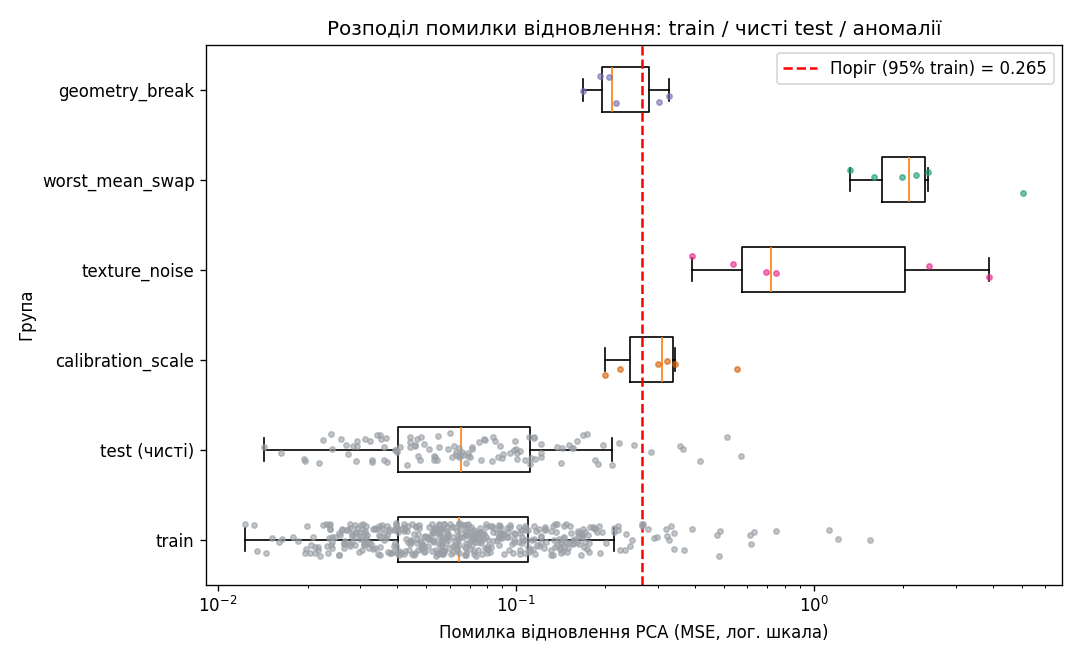

In [17]:
thr_rec = det.thresholds["rec"]
rows = [{"група": "train (n=455)", "n": len(sc_tr), "медіана": sc_tr.score_rec.median(), "p95": sc_tr.score_rec.quantile(0.95), "макс": sc_tr.score_rec.max()}]
m_clean = ~y_an
rows.append({"група": "test, чисті (n=90)", "n": int(m_clean.sum()), "медіана": sc_te.score_rec[m_clean].median(),
             "p95": sc_te.score_rec[m_clean].quantile(0.95), "макс": sc_te.score_rec[m_clean].max()})
for k_ in ["calibration_scale", "geometry_break", "worst_mean_swap", "texture_noise"]:
    s = sc_te.score_rec[kind == k_]
    rows.append({"група": k_, "n": len(s), "медіана": s.median(), "p95": s.quantile(0.95), "макс": s.max()})
dist = pd.DataFrame(rows)
dist["медіана / поріг"] = dist["медіана"] / thr_rec
display(dist.round(4))
print(f"Поріг rec (95-й перцентиль чистого train) = {thr_rec:.4f}")
show_fig("08_reconstruction_error_distributions.png", 800)

**Висновки.**

* На train медіана похибки відновлення — 0.0645, 95-й перцентиль — **0.2647**, максимум — 1.5419: розподіл правосторонній, що видно на лог-шкалі рисунка 8.
  Чисті test-об'єкти мають схожу медіану (0.0663) і максимум 0.5723; їхній p95 (0.3249) трохи вищий за train-ий, тож перенесення порога з train на test коректне, але дає дещо більше 5 % позначених (розділ 14).
* Аномалії різних типів зсувають розподіл по-різному. `worst_mean_swap` (медіана 2.097 = 7.9 порога) і `texture_noise` (0.7185 = 2.7 порога) лежать далеко вище порога.
  `calibration_scale` (медіана 0.3106 = 1.17 порога) лише ледве перевищує його, а медіана `geometry_break` (0.2107 = 0.80 порога) лежить **нижче** порога — для цих двох типів розподіли аномалій значно перекриваються з правим хвостом чистих даних
  (причини — у розділі 15.1).

## 14. Калібрування порогів (завдання 3.15)

Порогів чотири (по одному на детектор): 95-й перцентиль скору на **чистому train**. Поріг не змінювався після перегляду test. Для комбінованого сигналу
(розділ 16) формула — `max(перцентиль IF-PCA, перцентиль rec)` — також задана в конфігурації й порогуються її train-значення тим самим квантилем.
Явно рахуємо, скільки train- і test-об'єктів позначено.

In [18]:
fc = pd.read_csv(RES / "flagged_counts.csv")
display(fc.round(4))
fc_pct = pd.DataFrame({
    "detector": fc.detector,
    "train, %": 100 * fc.train_flagged / fc.train_n,
    "test чисті, %": 100 * fc.test_clean_flagged / fc.test_clean_n,
    "test аномалії (recall), %": 100 * fc.test_anomalies_flagged / fc.test_anomalies_n,
    "test без змін (114), %": 100 * fc.test_unmodified_flagged / fc.test_unmodified_n,
})
display(fc_pct.round(2))
# чи були серед 24 об'єктів ДО внесення аномалій позначені?
orig24 = sc_te_clean.loc[y_an.astype(bool)]
print("Позначено серед тих самих 24 об'єктів ДО внесення аномалій:",
      {d: int(orig24[f"flag_{d}"].sum()) for d in U.DETECTORS})

,detector,threshold,train_flagged,train_n,test_clean_flagged,test_clean_n,test_anomalies_flagged,test_anomalies_n,test_unmodified_flagged,test_unmodified_n
0,if30,0.5462,23,455,4,90,4,24,4,114
1,ifpca,0.5486,23,455,2,90,1,24,2,114
2,rec,0.2647,23,455,6,90,18,24,6,114
3,combined,0.9626,22,455,6,90,16,24,6,114


,detector,"train, %","test чисті, %","test аномалії (recall), %","test без змін (114), %"
0,if30,5.05,4.44,16.67,3.51
1,ifpca,5.05,2.22,4.17,1.75
2,rec,5.05,6.67,75.00,5.26
3,combined,4.84,6.67,66.67,5.26


Позначено серед тих самих 24 об'єктів ДО внесення аномалій: {'if30': 0, 'ifpca': 0, 'rec': 0, 'combined': 0}


**Висновки.**

* На **train** позначено **23 з 455** (5.05 %) для IF30, IFPCA і rec та **22 з 455** для комбінованого скору: це механічний наслідок порога на 95-му перцентилі
  (0.05 × 455 = 22.75), а не якість детектора.
* На **чистому test** (90 об'єктів) позначено: IF30 — 4 (4.4 %), IFPCA — 2 (2.2 %), rec — **6 (6.7 %)**, комбінований — 6 (6.7 %). Тобто частота хибних тривог на нових чистих даних
  близька до 5 % (rec трохи вище — 6.7 % при n = 90 відповідає лише 6 об'єктам, різниця статистично неістотна).
* На **всьому незмінному test (114)** позначено ті самі 4 / 2 / 6 / 6 об'єктів: **жоден із 24 об'єктів, до того як їх спотворили, не позначався**, тож усі позначення аномалій у модифікованому test спричинені саме втручанням.
* На **аномаліях**: IF30 позначив 4 з 24, IFPCA — 1 з 24, rec — **18 з 24**, комбінований — 16 з 24.
* Реалістичне навантаження для ручної перевірки у штатному режимі (без аномалій) — близько **5 %** потоку (6 з 114 = 5.3 % для rec на незмінному test; 23 з 455 = 5.05 % на train).

## 15. Оцінювання детекторів (завдання 3.16)

Для контрольованого test (24 аномалії / 90 чистих): ROC-AUC, Average Precision, precision, recall, F1, precision@k ($k=24$ — кількість істинних аномалій), матриця помилок,
recall за типом, Jaccard top-$k$ і таблиця розбіжностей рішень IF30 / IFPCA. Базовий рівень AP для випадкового скору дорівнює частці аномалій: 24/114 = 0.2105.

,detector,roc_auc,average_precision,precision,recall,f1,precision_at_k,k,n_flagged,tp,fp,fn,tn,threshold
0,if30,0.7889,0.4910,0.5000,0.1667,0.2500,0.4583,24,8,4,4,20,86,0.5462
1,ifpca,0.6722,0.3964,0.3333,0.0417,0.0741,0.2917,24,3,1,2,23,88,0.5486
2,rec,0.9616,0.8631,0.7500,0.7500,0.7500,0.7500,24,24,18,6,6,84,0.2647
3,combined,0.9565,0.8429,0.7273,0.6667,0.6957,0.7500,24,22,16,6,8,84,0.9626


Базовий AP (частка аномалій) = 0.2105

if30: поріг = 0.5462


,позначено,не позначено
факт: аномалія,4,20
факт: чистий,4,86



ifpca: поріг = 0.5486


,позначено,не позначено
факт: аномалія,1,23
факт: чистий,2,88



rec: поріг = 0.2647


,позначено,не позначено
факт: аномалія,18,6
факт: чистий,6,84



combined: поріг = 0.9626


,позначено,не позначено
факт: аномалія,16,8
факт: чистий,6,84


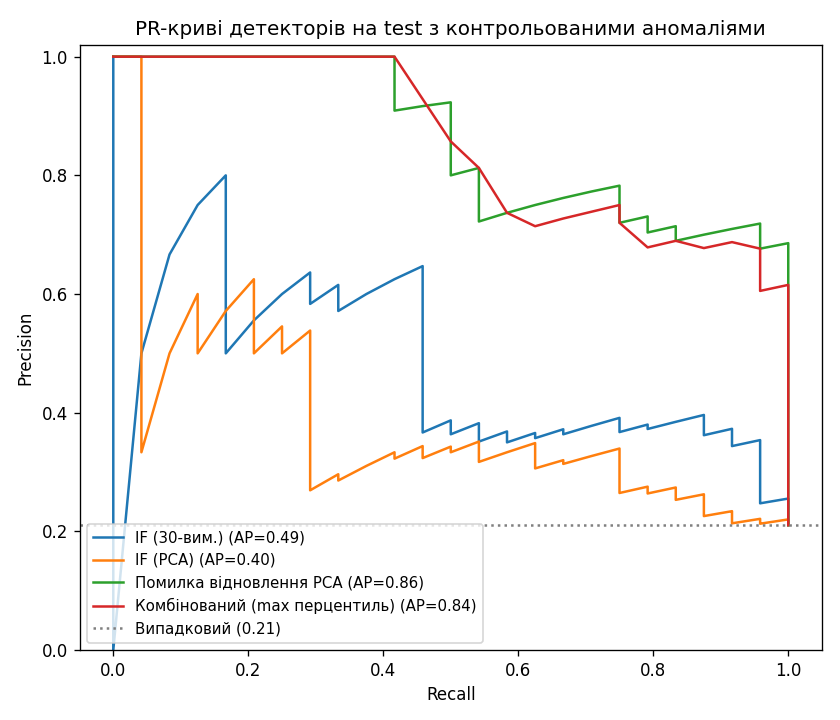

In [19]:
display(metrics.round(4))
print("Базовий AP (частка аномалій) =", round(24 / 114, 4))

# матриці помилок (рядки — факт, стовпці — рішення детектора)
for d in U.DETECTORS:
    r = metrics.set_index("detector").loc[d]
    cm = pd.DataFrame([[r.tp, r.fn], [r.fp, r.tn]], index=["факт: аномалія", "факт: чистий"],
                      columns=["позначено", "не позначено"]).astype(int)
    print(f"\n{d}: поріг = {r.threshold:.4f}")
    display(cm)
show_fig("09_anomaly_pr_curves.png", 700)

,kind,n,recall_if30,recall_ifpca,recall_rec,recall_combined
0,calibration_scale,6,0.0000,0.0000,0.6667,0.5000
1,geometry_break,6,0.0000,0.0000,0.3333,0.1667
2,worst_mean_swap,6,0.5000,0.0000,1.0000,1.0000
3,texture_noise,6,0.1667,0.1667,1.0000,1.0000


Jaccard top-24 (IF30 vs IFPCA) = 0.4545 (спільних об'єктів: 15 з 24, об'єднання 33)
Jaccard top-24 для інших пар: {'if30 vs ifpca': 0.4545, 'if30 vs rec': 0.4545, 'ifpca vs rec': 0.2973, 'rec vs combined': 0.92, 'ifpca vs combined': 0.3333}
Істинних аномалій у top-24 за IF30/IFPCA: {'if30': 11, 'ifpca': 7}


,group,n,both,only_if30,only_ifpca,none
0,anomalies,24,0,4,1,19
1,clean,90,2,2,0,86


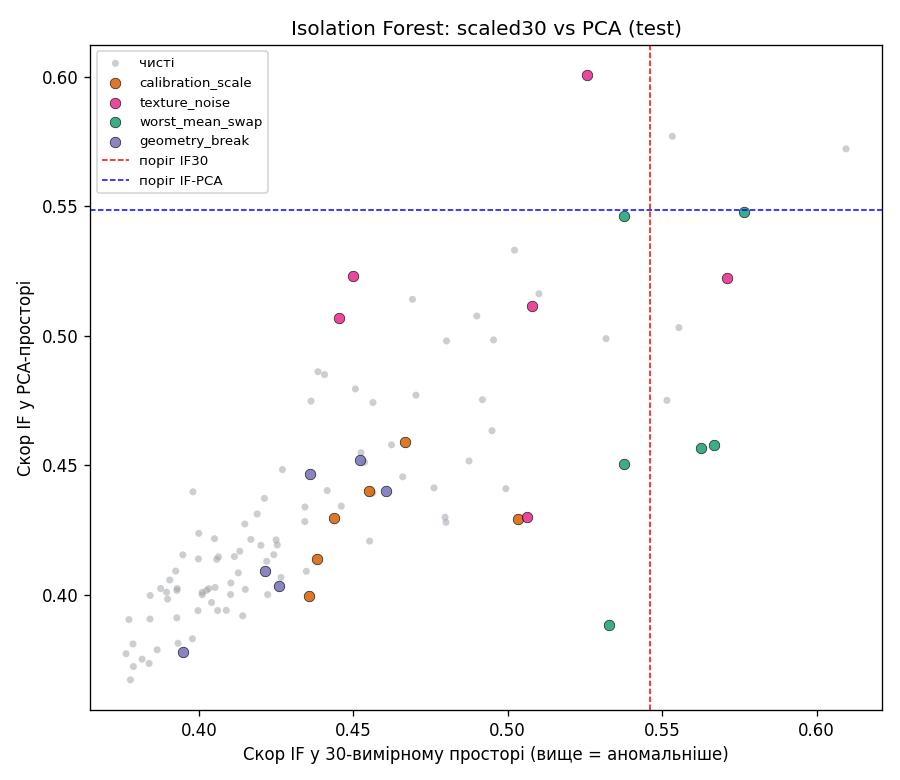

In [20]:
rbk = pd.read_csv(RES / "anomaly_recall_by_kind.csv").set_index("kind").loc[list(cfg["anomalies"]["kinds"])].reset_index()
display(rbk.round(4))

k_top = int(y_an.sum())
jac = U.top_k_jaccard(sc_te.score_if30, sc_te.score_ifpca, k_top)
top30 = set(np.argsort(-sc_te.score_if30.to_numpy(), kind="stable")[:k_top])
topp = set(np.argsort(-sc_te.score_ifpca.to_numpy(), kind="stable")[:k_top])
print(f"Jaccard top-{k_top} (IF30 vs IFPCA) = {jac:.4f} (спільних об'єктів: {len(top30 & topp)} з {k_top}, об'єднання {len(top30 | topp)})")
jac_rows = {f"{a} vs {b}": round(U.top_k_jaccard(sc_te[f"score_{a}"], sc_te[f"score_{b}"], k_top), 4)
            for a, b in [("if30", "ifpca"), ("if30", "rec"), ("ifpca", "rec"), ("rec", "combined"), ("ifpca", "combined")]}
print("Jaccard top-24 для інших пар:", jac_rows)
tp_top = {n: len(set(np.argsort(-sc_te[f'score_{n}'].to_numpy(), kind='stable')[:k_top]) & set(np.where(y_arr)[0])) for n in ('if30', 'ifpca')}
print("Істинних аномалій у top-24 за IF30/IFPCA:", tp_top)

dis = pd.read_csv(RES / "if_disagreement.csv")
display(dis)
show_fig("10_if_score_scaled_vs_pca.png", 800)

**Таблиця метрик (test, 24 аномалії / 90 чистих).**

| Детектор | ROC-AUC | AP | precision | recall | F1 | precision@24 | позначено | TP / FP / FN / TN |
|----------|---------|----|-----------|--------|----|--------------|-----------|-------------------|
| IF (30-вим.) | 0.7889 | 0.4910 | 0.5000 | 0.1667 | 0.2500 | 0.4583 | 8 | 4 / 4 / 20 / 86 |
| IF (PCA, 6-вим.) | 0.6722 | 0.3964 | 0.3333 | 0.0417 | 0.0741 | 0.2917 | 3 | 1 / 2 / 23 / 88 |
| **Помилка відновлення** | **0.9616** | **0.8631** | **0.7500** | **0.7500** | **0.7500** | **0.7500** | 24 | 18 / 6 / 6 / 84 |
| Комбінований | 0.9565 | 0.8429 | 0.7273 | 0.6667 | 0.6957 | 0.7500 | 22 | 16 / 6 / 8 / 84 |

**Висновки.**

* **Похибка відновлення — найкращий детектор у цьому експерименті** за всіма ранговими й пороговими метриками: AUC 0.9616, AP 0.8631 (проти базового 0.2105), recall 0.75 з precision 0.75.
  Обидва Isolation Forest значно слабші: AP 0.4910 (IF30) і 0.3964 (IFPCA); IFPCA майже нічого не позначає на порозі (3 об'єкти, recall 0.0417 = 1 з 24).
* **Редукція змінила результат у протилежний від «інтуїтивного» бік для Isolation Forest.** Припущення «після PCA ліс працюватиме краще, бо шумові ознаки видалено» **не підтвердилось**:
  AP знизилась з 0.4910 до 0.3964, recall — з 0.1667 до 0.0417, AUC — з 0.7889 до 0.6722. Пояснення: PCA залишає лише 6 «головних» напрямів; відхилення, ортогональні до цього підпростору (ті, що створюють геометричні й схемні помилки),
  у `Z` **зникають повністю**, і ліс у PCA-просторі їх просто не бачить. Помилка відновлення, навпаки, вимірює саме цю втрачену частину. Це не доводить, що PCA завжди шкодить IF, — лише що за цих типів аномалій і $q=6$ він шкодить.
* **Recall за типом аномалій:**

  | Тип | IF30 | IFPCA | rec | комбінований |
  |-----|------|-------|-----|--------------|
  | calibration_scale | 0.0000 | 0.0000 | 0.6667 | 0.5000 |
  | geometry_break | 0.0000 | 0.0000 | 0.3333 | 0.1667 |
  | worst_mean_swap | 0.5000 | 0.0000 | 1.0000 | 1.0000 |
  | texture_noise | 0.1667 | 0.1667 | 1.0000 | 1.0000 |

  Isolation Forest у початкових координатах не позначає **жодної** `calibration_scale` і `geometry_break`: після масштабування кожна окрема ознака лишається в діапазоні, спостережуваному на train
  (збільшення радіуса у 1.6 раза дає значення, типові для великих пухлин), а аномальність полягає у **співвідношеннях** ознак, які осьово-паралельні розбиття лісу майже не помічають.
* **Рисунок 10** (скори IF30 і IFPCA на test): скори сильно корельовані — хмара чистих об'єктів лежить уздовж діагоналі, а більшість `calibration_scale` і `geometry_break` розміщена **всередині цієї хмари** (нижній лівий кут), тобто обидва ліси
  не відрізняють їх від норми. За порогом IF30 (правіше червоної лінії) лежать 3 × `worst_mean_swap` і 1 × `texture_noise`; за порогом IFPCA — лише 1 × `texture_noise`; два swap-об'єкти (id 247 і 537) недотягують до порога IFPCA на 0.2–0.4 %.
  Чисті об'єкти, позначені обома лісами, — id 461 і 504; лише IF30 — ще 180 і 567.
* **Jaccard top-24** між IF30 та IFPCA дорівнює **0.4545** (15 спільних з 24, об'єднання 33): ранжування помітно розходяться. Для порівняння: Jaccard IF30 vs rec — 0.4545, IFPCA vs rec — **0.2973**
  (найменше узгодження), rec vs combined — 0.92. Серед top-24 за IF30 — 11 істинних аномалій, за IFPCA — лише 7 (precision@24 = 0.4583 і 0.2917).
  **Розбіжність рішень:** серед 24 аномалій обидва IF разом не позначили жодної (`both = 0`), лише IF30 — 4, лише IFPCA — 1, **жоден — 19**; серед 90 чистих: обидва — 2, лише IF30 — 2, лише IFPCA — 0, жоден — 86.
  Обидва IF не збігаються на істинних аномаліях (IF30 «знаходить» 4, IFPCA — 1, перетин порожній), тобто вони шукають різні типи відхилень, але обидва — слабко.
* **Матриця помилок rec:** TP 18, FP 6, FN 6, TN 84. Помилковою тривогою позначено 6 з 90 чистих (6.7 %); пропущено 6 з 24 аномалій (25 %). Позбутися всіх FP лише підняттям порога неможливо без втрати recall: найвищий скор серед чистих test — 0.5723, а всі скори `calibration_scale` (максимум 0.5524) і `geometry_break` (максимум 0.3282) лежать нижче цього значення.

### 15.1. Конкретні false positives та false negatives (завдання 3.14 / 3.16)

**False positives** — чисті test-об'єкти, позначені `rec` або комбінованим детектором (діагноз показується лише для аудиту). **False negatives** — пропущені аномалії з відношенням скору до порога.

In [21]:
fp = pd.read_csv(RES / "false_positives.csv")
fn = pd.read_csv(RES / "false_negatives.csv")
with pd.option_context("display.max_columns", 40):
    display(fp.round(3))
res_feats = pd.concat([fp[f"feature_{j}"] for j in (1, 2, 3)])
print(f"FP: {len(fp)} об'єктів; серед них злоякісні (аудит): {int((fp.diagnosis_audit_only == 'malignant').sum())}, доброякісні: {int((fp.diagnosis_audit_only == 'benign').sum())}")
print(f"Серед {len(res_feats)} найбільших залишків (3 на об'єкт) ознак *_se: {int(res_feats.str.endswith('_se').sum())}; ознаки: {res_feats.value_counts().to_dict()}")
print("Об'єкти, позначені обома detectors rec та combined:", sorted(fp.loc[fp.flag_rec & fp.flag_combined, 'id']),
      "| лише rec:", sorted(fp.loc[fp.flag_rec & ~fp.flag_combined, 'id']), "| лише combined:", sorted(fp.loc[~fp.flag_rec & fp.flag_combined, 'id']))

print("\nFN: кількість пропущених за детектором і типом")
display(fn.groupby(["detector", "kind"]).size().unstack(fill_value=0))
print("FN детектора rec (скор / поріг):")
display(fn[fn.detector == "rec"].round(4).reset_index(drop=True))

,id,flag_rec,flag_combined,score_rec,diagnosis_audit_only,feature_1,residual_1,feature_2,residual_2,feature_3,residual_3
0,288,True,True,0.572,benign,concave_points_se,1.945,symmetry_mean,1.833,smoothness_se,1.429
1,528,True,True,0.357,benign,texture_se,1.760,concave_points_se,1.618,smoothness_se,-1.126
2,417,True,False,0.285,malignant,radius_se,1.413,perimeter_se,0.907,fractal_dimension_worst,0.856
3,568,True,True,0.364,benign,smoothness_mean,-1.479,radius_se,1.068,perimeter_se,1.058
4,83,True,True,0.513,malignant,concavity_se,-1.573,fractal_dimension_se,1.288,smoothness_se,-1.241
5,461,False,True,0.249,malignant,radius_se,1.891,symmetry_se,-0.926,texture_se,-0.660
6,504,True,True,0.416,benign,smoothness_se,-1.942,smoothness_mean,1.469,fractal_dimension_mean,1.122


FP: 7 об'єктів; серед них злоякісні (аудит): 3, доброякісні: 4
Серед 21 найбільших залишків (3 на об'єкт) ознак *_se: 16; ознаки: {'smoothness_se': 4, 'radius_se': 3, 'concave_points_se': 2, 'texture_se': 2, 'smoothness_mean': 2, 'perimeter_se': 2, 'concavity_se': 1, 'symmetry_mean': 1, 'fractal_dimension_se': 1, 'symmetry_se': 1, 'fractal_dimension_worst': 1, 'fractal_dimension_mean': 1}
Об'єкти, позначені обома detectors rec та combined: [83, 288, 504, 528, 568] | лише rec: [417] | лише combined: [461]

FN: кількість пропущених за детектором і типом


kind,calibration_scale,geometry_break,texture_noise,worst_mean_swap
detector,,,,
combined,3,5,0,0
if30,6,6,5,3
ifpca,6,6,5,6
rec,2,4,0,0


FN детектора rec (скор / поріг):


,detector,id,kind,score,threshold,score_over_threshold
0,rec,428,calibration_scale,0.1998,0.2647,0.7548
1,rec,73,geometry_break,0.2163,0.2647,0.8172
2,rec,439,geometry_break,0.1916,0.2647,0.7239
3,rec,434,geometry_break,0.1683,0.2647,0.6358
4,rec,321,geometry_break,0.2050,0.2647,0.7743
5,rec,296,calibration_scale,0.2232,0.2647,0.8433


In [22]:
# Яка частка зсуву, внесеного аномалією, лежить у збереженому PCA-підпросторі (її rec «не бачить»)?
V = pca6.components_
rows = []
for k_ in ["calibration_scale", "geometry_break", "worst_mean_swap", "texture_noise"]:
    idx = np.where(kind == k_)[0]
    shares, ratios = [], []
    for i in idx:
        dlt = Xs_te[i] - Xs_te_clean[i]
        shares.append(float(((V @ dlt) ** 2).sum() / (dlt ** 2).sum()))
        ratios.append(float(sc_te.score_rec.iloc[i] / thr_rec))
    norms = np.array([np.linalg.norm(Xs_te[i] - Xs_te_clean[i]) for i in idx])
    rows.append({"тип": k_, "норма зсуву ||Δ||": norms.mean(),
                 "частка зсуву в підпросторі PCA": float(np.mean(shares)),
                 "енергія поза підпростором ||Δ||²(1-частка)/30": float(np.mean(norms ** 2 * (1 - np.array(shares)) / 30)),
                 "середній rec/поріг": float(np.mean(ratios)), "мін rec/поріг": float(np.min(ratios))})
display(pd.DataFrame(rows).round(3))
print(f"Різниця поріг - медіана train rec: {thr_rec - sc_tr.score_rec.median():.4f}")

for d in ("if30", "ifpca", "rec"):
    r_ = fn.loc[fn.detector == d, "score_over_threshold"]
    print(f"{d}: пропущено {len(r_)}; score/поріг у діапазоні [{r_.min():.3f}, {r_.max():.3f}]")
fp_if = {d: sorted(map(int, sc_te.id[(~y_arr) & sc_te[f"flag_{d}"]])) for d in ("if30", "ifpca")}
print("Чисті об'єкти, позначені IF (у false_positives.csv не входять):", fp_if)

,тип,норма зсуву ||Δ||,частка зсуву в підпросторі PCA,енергія поза підпростором ||Δ||²(1-частка)/30,середній rec/поріг,мін rec/поріг
0,calibration_scale,4.775,0.773,0.172,1.220,0.755
1,geometry_break,2.526,0.211,0.168,0.889,0.636
2,worst_mean_swap,8.872,0.159,2.399,9.194,5.020
3,texture_noise,7.037,0.339,1.389,5.479,1.476


Різниця поріг - медіана train rec: 0.2002
if30: пропущено 20; score/поріг у діапазоні [0.723, 0.984]
ifpca: пропущено 23; score/поріг у діапазоні [0.689, 0.998]
rec: пропущено 6; score/поріг у діапазоні [0.636, 0.843]
Чисті об'єкти, позначені IF (у false_positives.csv не входять): {'if30': [180, 461, 504, 567], 'ifpca': [461, 504]}


**Пояснення false positives (7 об'єктів).**

* Позначені чисті test-об'єкти: **288, 528, 568, 83, 504** (обидва детектори — rec і комбінований), **417** (лише rec), **461** (лише комбінований). За аудитом 3 з 7 — злоякісні (417, 83, 461), 4 — доброякісні.
  Тобто FP — не обов'язково «погані» об'єкти: це **природно нетипові** випадки без технічної помилки.
* **Причина — важкі хвости `*_se`.** Серед 21 найбільшого залишку (3 ознаки × 7 об'єктів) **16 — ознаки стандартних похибок** (`smoothness_se` ×4, `radius_se` ×3, `concave_points_se`, `texture_se`, `perimeter_se` по ×2, `concavity_se`, `fractal_dimension_se`, `symmetry_se`);
  решта 5 — `smoothness_mean` ×2, `symmetry_mean`, `fractal_dimension_mean`, `fractal_dimension_worst`. Саме `*_se` лишились асиметричними після `log1p` (розділ 3) і найгірше описуються низьковимірним підпростором. Наприклад, об'єкт **288** (score_rec 0.5723, у 2.2 раза вище порога): залишки
  `concave_points_se` +1.95, `symmetry_mean` +1.83, `smoothness_se` +1.43 — рідкісне поєднання без розмірних аномалій. Об'єкт **83** (злоякісний): `concavity_se` −1.57, `fractal_dimension_se` +1.29, `smoothness_se` −1.24.
* Висновок для практики: **rec-тривога — це «об'єкт, що погано пояснюється 6 головними компонентами»**, а не «помилка вимірювання»; такі об'єкти потребують перегляду експертом, а не автоматичного відкидання (3 з 7 злоякісні).

**Пояснення false negatives (rec пропустив 6 з 24).**

* Усі 6 пропусків rec: **2 × `calibration_scale`** (id 428, 296) і **4 × `geometry_break`** (id 73, 439, 434, 321). Відношення скору до порога — від 0.636 до 0.843, тобто це не «зовсім непомічені», а об'єкти, що не дотягнули до порога на 16–36 %.
* Пояснення дає таблиця «частка зсуву в підпросторі PCA». Для `calibration_scale` (узгоджене збільшення розмірних ознак) **77.3 %** зсуву лежить у збереженому підпросторі (уздовж PC1 — осі «розміру»): PCA «відновлює» такий об'єкт як просто більший, але правдоподібний.
  Для `geometry_break` у підпросторі лише 21.1 % зсуву (решта — у залишку), але **сам зсув малий**: змінюються 2 колонки з 30, норма $\|\Delta\|$ = 2.53 проти 8.87 у `worst_mean_swap`.
  Додана у залишок «енергія» $\|\Delta\|^2(1-	ext{частка})/30$ для обох типів — близько 0.17 (див. таблицю), тоді як різниця між порогом і типовою (медіанною) похибкою становить 0.2647 − 0.0645 ≈ 0.20; тому цей зсув лише в частини об'єктів
  перетинає поріг (середнє `rec/поріг` 1.22 та 0.89). Для `worst_mean_swap` і `texture_noise` додана енергія (2.40 і 1.39) у 8–14 разів більша, і вони ловляться на 100 %.
* Isolation Forest пропускає **20 (IF30) і 23 (IFPCA)** аномалії з 24. Їхні скори лежать у діапазоні 72–98 % (IF30) і 69–100 % (IFPCA) від порога (див. вивід нижче і `false_negatives.csv`) — такі об'єкти виглядають як звичайні.

## 16. Комбінований сигнал (завдання 3.17)

**Формула (зафіксована в конфігурації `combined_rule = "max_percentile"` до test-аудиту):**
$$s_{comb}(x)=\max\bigl(u_{IF\text{-}PCA}(x),\,u_{rec}(x)\bigr),\qquad u(s)=\frac{\#\{s_{train}\le s\}}{n_{train}},$$
де $u$ — емпіричний перцентиль скору відносно **train**-скорів; поріг — 95-й перцентиль $s_{comb}$ на train. Перцентиль потрібен, бо IF-скор і похибка відновлення мають різні шкали.

Поріг combined = 0.9626; діапазон перцентилів на test: [0.020, 1.000]
TP: rec = 18 | combined = 16 | ifpca = 1 | if30 = 4
combined ⊂ rec: True | знайдено rec, але не combined: [284, 519] | знайдено combined, але не rec: []
Знайдено IFPCA, але не rec: [] | знайдено IF30, але не rec: []

Об'єктів test з u_rec = 1.0 (вище максимуму train): 7 (з них аномалій 7); з u_ifpca = 1.0: 0; з combined = 1.0: 7


,id,kind,u_if,u_rec,score_combined,score_rec
0,247,worst_mean_swap,0.9451,1.0000,1.0000,5.0558
1,564,texture_noise,0.9297,1.0000,1.0000,3.8884
2,95,texture_noise,0.5802,1.0000,1.0000,2.4508
3,408,worst_mean_swap,0.7670,1.0000,1.0000,2.4280
4,537,worst_mean_swap,0.9451,1.0000,1.0000,2.2164
5,375,worst_mean_swap,0.7385,1.0000,1.0000,1.9776
6,298,worst_mean_swap,0.1099,1.0000,1.0000,1.5964
7,70,worst_mean_swap,0.7670,0.9978,0.9978,1.3288
8,535,texture_noise,0.9099,0.9912,0.9912,0.7470
9,140,texture_noise,0.9802,0.9912,0.9912,0.6899



Втрачені combined аномалії: [284, 519] | u_rec = [0.9604, 0.9604] | u_ifpca = [0.7516, 0.5758] | поріг rec відповідає перцентилю 0.95, поріг combined = 0.9626


Скільки train-об'єктів мають u_ifpca>0.95 / u_rec>0.95 / max>0.95: 23 23 31

Чисті об'єкти, позначені лише combined: [461] | u_ifpca = [0.967] | u_rec = [0.9473] | поріг combined = 0.9626


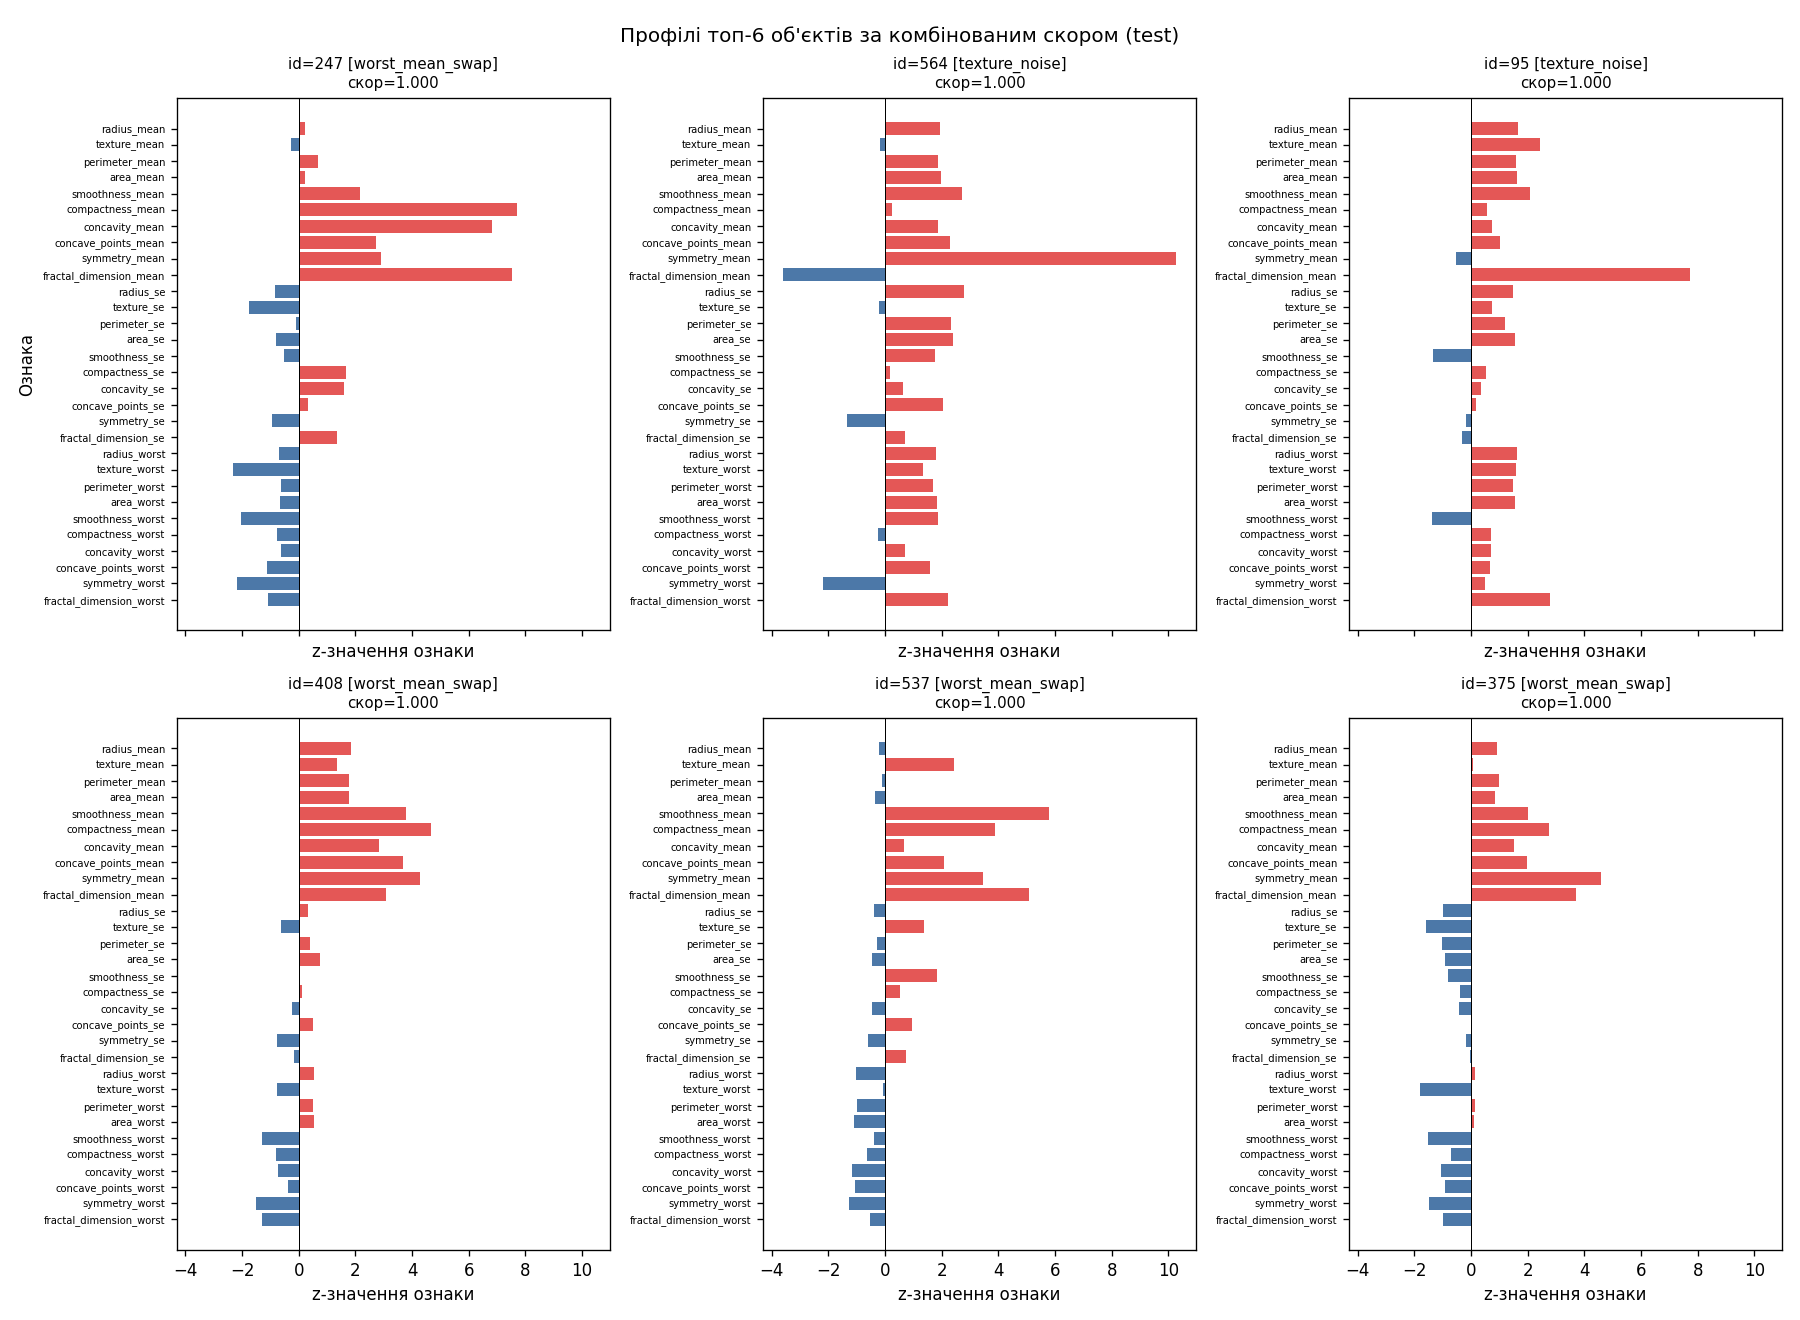

In [23]:
u_if = U.empirical_percentile(det.sorted_train["ifpca"], sc_te.score_ifpca)
u_rec = U.empirical_percentile(det.sorted_train["rec"], sc_te.score_rec)
assert np.allclose(np.maximum(u_if, u_rec), sc_te.score_combined)
print(f"Поріг combined = {det.thresholds['combined']:.4f}; діапазон перцентилів на test: [{sc_te.score_combined.min():.3f}, {sc_te.score_combined.max():.3f}]")

# хто знайдений: множини істинних позитивів
tp = {d: set(sc_te.id[y_an.astype(bool) & sc_te[f"flag_{d}"]]) for d in U.DETECTORS}
print("TP: rec =", len(tp["rec"]), "| combined =", len(tp["combined"]), "| ifpca =", len(tp["ifpca"]), "| if30 =", len(tp["if30"]))
print("combined ⊂ rec:", tp["combined"] <= tp["rec"], "| знайдено rec, але не combined:", sorted(tp["rec"] - tp["combined"], key=int),
      "| знайдено combined, але не rec:", sorted(tp["combined"] - tp["rec"]))
print("Знайдено IFPCA, але не rec:", sorted(tp["ifpca"] - tp["rec"]), "| знайдено IF30, але не rec:", sorted(tp["if30"] - tp["rec"]))

# насичення перцентиля
sat_rec = int((u_rec == 1.0).sum()); sat_if = int((u_if == 1.0).sum()); sat_c = int((sc_te.score_combined == 1.0).sum())
print(f"\nОб'єктів test з u_rec = 1.0 (вище максимуму train): {sat_rec} (з них аномалій {int(((u_rec == 1.0) & y_arr).sum())}); "
      f"з u_ifpca = 1.0: {sat_if}; з combined = 1.0: {sat_c}")
tie = sc_te.assign(kind=kind, u_if=u_if, u_rec=u_rec)
display(tie.sort_values(["score_combined", "score_rec"], ascending=False).head(10)[["id", "kind", "u_if", "u_rec", "score_combined", "score_rec"]].round(4).reset_index(drop=True))

# чому combined втратив 2 аномалії rec: його поріг у шкалі перцентилів строгіший
lost = [284, 519]
print("\nВтрачені combined аномалії:", lost, "| u_rec =", u_rec[sc_te.id.isin(lost).to_numpy()].round(4).tolist(),
      "| u_ifpca =", u_if[sc_te.id.isin(lost).to_numpy()].round(4).tolist(),
      f"| поріг rec відповідає перцентилю 0.95, поріг combined = {det.thresholds['combined']:.4f}")
print("Скільки train-об'єктів мають u_ifpca>0.95 / u_rec>0.95 / max>0.95:",
      int((U.empirical_percentile(det.sorted_train['ifpca'], det.train_scores['ifpca']) > 0.95).sum()),
      int((U.empirical_percentile(det.sorted_train['rec'], det.train_scores['rec']) > 0.95).sum()),
      int((det.train_scores['combined'] > 0.95).sum()))

# випадок, де combined позначив чистий об'єкт, а rec — ні
only_c = sc_te[(~y_an.astype(bool)) & sc_te.flag_combined & ~sc_te.flag_rec]
print("\nЧисті об'єкти, позначені лише combined:", only_c.id.tolist(),
      "| u_ifpca =", u_if[only_c.index].round(4).tolist(), "| u_rec =", u_rec[only_c.index].round(4).tolist(), "| поріг combined =", round(det.thresholds["combined"], 4))
show_fig("11_top_anomalies_profiles.png", 900)

**Висновки.**

* **Порівняння за типами аномалій** (recall): `texture_noise` — 1.00 у rec і combined (обидва IF — 0.17); `worst_mean_swap` — 1.00 / 1.00 (IF30 — 0.50, IFPCA — 0); `calibration_scale` — rec **0.667** проти combined **0.500**;
  `geometry_break` — rec **0.333** проти combined **0.167**. Загальні показники: AP 0.8631 → 0.8429 (rec → combined), AUC 0.9616 → 0.9565, recall 0.75 → 0.667, F1 0.75 → 0.696, precision@24 однакова (0.75); Jaccard top-24 між їхніми рейтингами — 0.92.
  Отже **у цьому експерименті комбінування НЕ допомогло**: множина знайдених combined аномалій (16) є підмножиною rec (18): combined не знайшов жодної аномалії, яку пропустив rec, але втратив дві (id 284 і 519).
  Складники IF також не додали нічого: усі 4 аномалії IF30 і 1 аномалія IFPCA rec уже знаходить.
* **Чому не допомогло.**
  1. **Слабка складова.** IF-PCA має AUC лише 0.6722 і знаходить 1 аномалію з 24; оператор `max` додає його шум до сильного сигналу rec — чистий об'єкт **461** (u_ifpca = 0.967, u_rec = 0.9473) став єдиним FP лише комбінованого детектора.
  2. **`max` двох перцентилів підвищує поріг.** На train по 23 об'єкти мають $u_{IF}>0.95$ та $u_{rec}>0.95$, але $\max(\cdot)>0.95$ — вже 31 об'єкт; тому 95-й перцентиль самого max-скору становить **0.9626**, а не 0.95. У шкалі rec це строгіший поріг:
     аномалії 284 і 519 мають $u_{rec}=0.9604$ (вище 0.95 — rec їх позначає — але нижче 0.9626 — combined пропускає), $u_{IF-PCA}$ у них лише 0.7516 і 0.5758.
  3. **Насичення перцентиля.** $u(s)$ обмежене зверху значенням 1.0: усі test-об'єкти, чий скор перевищує максимум train, отримують $u=1$ незалежно від того, наскільки вони аномальні. У таблиці вище **7 об'єктів мають `score_combined = 1.0`**
     (усі — справжні аномалії: 5 × `worst_mean_swap`, 2 × `texture_noise`), хоча їхня похибка відновлення різниться у 3 рази (від 1.60 до 5.06). Тут це не зашкодило AP (усі 7 — істинні), але порядок серед них довільний (у рисунку 11 розв'язується вторинним ключем `score_rec`),
     а інформація про величину відхилення втрачена; на нових даних зі схожим «стелею» це погіршувало б ранжування.
     Саме ці нічиї показали, що перша версія `precision@k` (перші $k$ рядків стабільного `argsort`) залежала від порядку рядків; тепер `precision_at_k` бере очікувану частку аномалій серед об'єктів, що ділять $k$-те місце (тест `test_precision_at_k_ties_do_not_depend_on_row_order`). На цих даних значення не змінилося: усі 7 нічийних об'єктів лежать усередині top-24.
* **Коли об'єднання теоретично допомагає:** коли складові змістовні й доповнюють одна одну (одна ловить відхилення всередині підпростору, інша — поза ним). Тут IF-PCA працює лише з підпростором $Z$ і майже не бачить нічого; відхилення «в підпросторі»
  (`calibration_scale`) краще ловить IF30 за значеннями, але й він знаходить 0 з 6. Формулу зафіксовано за завданням 3.17 (IF у PCA-просторі + rec) до test-аудиту й після нього не змінювали — навіть коли результат виявився гіршим за rec.
* **Рисунок 11 (профілі top-6 за combined)** — це 4 × `worst_mean_swap` (id 247, 408, 537, 375) і 2 × `texture_noise` (564, 95), усі зі `score = 1.000`. У swap-об'єктів `*_mean` ознаки мають великі додатні z-значення (у id 247 `compactness_mean`, `concavity_mean`,
  `fractal_dimension_mean` ≈ 7–8), а `*_worst` — від'ємні: у позицію «середнього» записано «найгірше» значення, що значно більше за типове середнє, а в позицію «найгіршого» — менше. У `texture_noise` видно локальні викиди (id 564: `symmetry_mean` ≈ +10,
  `fractal_dimension_mean` ≈ −3.7; id 95: `fractal_dimension_mean` ≈ +7.8). Тобто rec не лише «знаходить», а й вказує, **які** ознаки розходяться, чого немає в скорі Isolation Forest.

## 17. Post-hoc чутливість до $q$ (діагностика, **не** використовувалась для вибору)

> **Це post-hoc діагностика на test.** Файл `posthoc_q_sensitivity.csv` показує, як змінився б rec-детектор за інших порогів дисперсії (0.80 → $q=4$, 0.95 → $q=10$). Вибір $q=6$ зроблено **до** цього аналізу за правилом з конфігурації;
> вибирати $q$ за recall на test-аномаліях означало б **leakage** (параметр підганяється під відкриті тестові мітки).

In [24]:
ph = pd.read_csv(RES / "posthoc_q_sensitivity.csv")
display(ph.round(4))
print("Приріст recall q=6 -> q=10:", round(float(ph.loc[ph.q == 10, "recall"].iloc[0] - ph.loc[ph.q == 6, "recall"].iloc[0]), 4),
      "= %d аномалій з 24" % round(24 * float(ph.loc[ph.q == 10, "recall"].iloc[0] - ph.loc[ph.q == 6, "recall"].iloc[0])))

,variance_threshold,q,roc_auc,average_precision,recall,precision,n_flagged
0,0.80,4,0.9319,0.8188,0.5417,0.8667,15
1,0.90,6,0.9616,0.8631,0.7500,0.7500,24
2,0.95,10,0.9792,0.9194,0.9167,0.8148,27


Приріст recall q=6 -> q=10: 0.1667 = 4 аномалій з 24


**Висновки.**

| Поріг дисперсії | $q$ | ROC-AUC | AP | recall | precision | позначено |
|-----------------|-----|---------|----|--------|-----------|-----------|
| 0.80 | 4 | 0.9319 | 0.8188 | 0.5417 | 0.8667 | 15 |
| **0.90 (робоче)** | **6** | 0.9616 | 0.8631 | 0.7500 | 0.7500 | 24 |
| 0.95 | 10 | 0.9792 | 0.9194 | 0.9167 | 0.8148 | 27 |

* Для даного набору контрольованих аномалій якість **зростає з $q$**: від $q=4$ до $q=10$ AP піднімається з 0.8188 до 0.9194, recall — з 0.5417 до 0.9167. Різниця між $q=6$ і $q=10$ — 4 аномалії з 24 (recall +0.1667).
* **Це не причина змінювати $q$.** (1) Вибір за test-метрикою — витік; $q=6$ зафіксовано до аномалій. (2) Вибірка мала (24 аномалії, крок recall = 0.0417), а аномалії — синтетичні й створені тим самим автором; на іншому типі спотворень залежність могла б бути іншою.
  (3) Тенденція зрозуміла структурно: при більшому $q$ у підпросторі залишається більше інформації про кореляції, а хвіст train-похибки (поріг) стискається (0.2647 → 0.1116 за таблицею розділу 5) — малі відхилення стають видимими.
  Але ціна — більша розмірність і ширша «зона нормальності» для шуму. Це **гіпотеза для окремого експерименту з відкладеною вибіркою**, а не результат, що обґрунтовує зміну протоколу.

## 18. Автоматичні тести (завдання 3.18)

`python -m unittest discover -s tests -v` (запускається з `lab05/`). Тести охоплюють вибір $q$ на штучному прикладі, форми `transform`/`inverse_transform`, неперетин id,
інваріантність ARI, відтворюваність аномалій, діапазони скорів/метрик, помилкові входи (`ValueError`), наявність артефактів і завантаження збереженого pipeline.

In [25]:
t0 = time.perf_counter()
tp_ = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"], cwd=ROOT, capture_output=True, text=True)
t_tests = time.perf_counter() - t0
out = (tp_.stdout + tp_.stderr).strip().splitlines()
print(f"returncode = {tp_.returncode}; час {t_tests:.0f} с")
print("\n".join(out[-14:]))
n_tests = int(re.search(r"Ran (\d+) tests?", "\n".join(out)).group(1))
n_ok = sum(1 for line in out if line.rstrip().endswith("ok"))
n_skip = sum(1 for line in out if "skipped" in line)
assert tp_.returncode == 0
print(f"\nТестів: {n_tests}; з маркером «ok»: {n_ok}; пропущено: {n_skip}")

returncode = 0; час 4 с
test_invalid_k (test_unsupervised_pipeline.TestJaccard.test_invalid_k) ... ok
test_known_value (test_unsupervised_pipeline.TestJaccard.test_known_value) ... ok
test_curve_matches_pca_reconstruction (test_unsupervised_pipeline.TestPCAAndPreprocessing.test_curve_matches_pca_reconstruction) ... ok
test_full_pca_reconstruction_is_exact (test_unsupervised_pipeline.TestPCAAndPreprocessing.test_full_pca_reconstruction_is_exact) ... ok
test_log1p_inverse_roundtrip_and_negative_values (test_unsupervised_pipeline.TestPCAAndPreprocessing.test_log1p_inverse_roundtrip_and_negative_values) ... ok
test_preprocessor_fitted_on_train_only (test_unsupervised_pipeline.TestPCAAndPreprocessing.test_preprocessor_fitted_on_train_only) ... ok
test_transform_inverse_shapes (test_unsupervised_pipeline.TestPCAAndPreprocessing.test_transform_inverse_shapes) ... ok
test_check_split_errors (test_unsupervised_pipeline.TestSplit.test_check_split_errors) ... ok
test_ids_disjoint_and_complete (te

**Висновки.** Усі **37** автоматичних тестів проходять (код повернення 0, статус `OK`, жодного пропущеного); їх кількість перевищує мінімум методички (8, з яких ≥ 2 на помилкові входи) — багато перевірок
стосуються саме методичних помилок unsupervised-pipeline: виток при масштабуванні (скейлер навчено на train), неперетин id, детермінованість генератора аномалій, `ValueError` на хибних порогах/конфігурації/кількості аномалій,
інваріантність ARI до перестановки кластерів, Hungarian-узгодження міток і завантаження `lr05_bundle.joblib` з прогнозом для нового пакета. Інтеграційний тест працює на реальних артефактах, створених першою клітинкою notebook.

## 19. Збережений pipeline: завантаження й прогноз для нового пакета

`artifacts/lr05_bundle.joblib` містить конфігурацію, препроцесор, PCA, обидві моделі K-Means, обидва Isolation Forest, train-скори та пороги.
`load_bundle` перевіряє наявність ключів; `predict_new` приймає **сирі** дані (той самий набір колонок) і повертає кластери в обох просторах та скори й прапорці всіх чотирьох детекторів.

In [26]:
bundle = U.load_bundle(ART / "lr05_bundle.joblib")
print("Ключі bundle:", sorted(bundle.keys()))
print("version:", bundle["version"], "| K:", bundle["selected_k"], "| порогів:", {k: round(v, 4) for k, v in bundle["thresholds"].items()})

batch5 = data.X_train.head(5)               # 5 сирих рядків із навчальної частини (id = індекс)
pred = U.predict_new(bundle, batch5)
display(pred.round(4))

# узгодженість з результатами експерименту
ref_c30 = st30.set_index("id").loc[batch5.index, "reference_cluster"].to_numpy()
ref_c6 = st6.set_index("id").loc[batch5.index, "reference_cluster"].to_numpy()
print("cluster_scaled30 збігається з object_stability_scaled30.csv:", bool(np.array_equal(pred.cluster_scaled30, ref_c30)))
print("cluster_pca збігається з object_stability_pca6.csv:", bool(np.array_equal(pred.cluster_pca, ref_c6)))
print("score_rec збігається з перерахунком у notebook:", bool(np.allclose(pred.score_rec, sc_tr.set_index("id").loc[batch5.index, "score_rec"])))
print("Усі числові значення скінченні:", bool(np.isfinite(pred.drop(columns=[c for c in pred.columns if c.startswith("flag_")]).to_numpy(float)).all()))

# захист від хибного входу
try:
    U.predict_new(bundle, batch5.drop(columns=["radius_mean"]))
except ValueError as e:
    print("\nЗапит без колонки radius_mean ->", "ValueError:", e)

Ключі bundle: ['config', 'detectors', 'feature_names', 'if30', 'ifpca', 'kmeans_pca', 'kmeans_scaled30', 'pca', 'preprocessor', 'selected_k', 'thresholds', 'train_scores', 'version']
version: 1.0.0 | K: {'scaled30': 2, 'pca6': 2} | порогів: {'if30': 0.5462, 'ifpca': 0.5486, 'rec': 0.2647, 'combined': 0.9626}


,id,cluster_scaled30,cluster_pca,score_if30,score_ifpca,score_rec,score_combined,flag_if30,flag_ifpca,flag_rec,flag_combined
0,546,1,0,0.4112,0.3892,0.0347,0.1934,False,False,False,False
1,432,0,1,0.4372,0.4064,0.1695,0.8945,False,False,False,False
2,174,1,0,0.4457,0.4457,0.0768,0.7165,False,False,False,False
3,221,1,0,0.3920,0.4126,0.0254,0.4132,False,False,False,False
4,289,1,0,0.3948,0.4340,0.0336,0.6198,False,False,False,False


cluster_scaled30 збігається з object_stability_scaled30.csv: True
cluster_pca збігається з object_stability_pca6.csv: True
score_rec збігається з перерахунком у notebook: True
Усі числові значення скінченні: True

Запит без колонки radius_mean -> ValueError: missing feature columns: ['radius_mean']


**Висновки.** Збережений pipeline завантажується без повторного навчання й дає прогноз для сирих рядків: для 5 об'єктів train кластери в обох просторах збігаються з еталонними мітками
(`object_stability_*.csv`), а `score_rec` — з перерахунком у notebook. Усі значення скінченні; відсутні колонки призводять до `ValueError` із переліком колонок. Номери кластерів у двох просторах — умовні й можуть
не збігатися для того самого об'єкта (див. розділ 10), тому для порівняння просторів використовують ARI, а не збіг номерів.

## 20. Інженерне рішення (завдання 3.19)

In [27]:
mm = metrics.set_index("detector")
# довірчі інтервали Вілсона (95 %) для recall / частки хибних тривог
def wilson(k, n):
    ci = binomtest(int(k), int(n)).proportion_ci(confidence_level=0.95, method="wilson")
    return f"{k}/{n} = {k / n:.3f} [{ci.low:.2f}; {ci.high:.2f}]"

print("recall rec на 24 аномаліях:", wilson(mm.loc["rec", "tp"], 24))
print("FPR rec на 90 чистих test:", wilson(mm.loc["rec", "fp"], 90))
print("recall IF30:", wilson(mm.loc["if30", "tp"], 24))
for kd, g in zip(rbk.kind, rbk.recall_rec):
    print(f"recall rec, {kd}: {wilson(round(g * 6), 6)}")

# розмір черги ручної перевірки
q_rec_te = int(mm.loc["rec", "n_flagged"])
print(f"\nrec позначає на модифікованому test: {q_rec_te} з 114 ({100 * q_rec_te / 114:.1f} %), з них аномалій {int(mm.loc['rec', 'tp'])};",
      f"на незмінному test: {int(fc.set_index('detector').loc['rec', 'test_unmodified_flagged'])} з 114 ({100 * fc.set_index('detector').loc['rec', 'test_unmodified_flagged'] / 114:.1f} %)")

# об'єкти для ручної перевірки: нестабільні кластерно + rec-позначені на train
rec_train_top = sc_tr.sort_values("score_rec", ascending=False).head(5)[["id", "score_rec"]]
print("\nТоп-5 train за rec:", rec_train_top.round(3).values.tolist())
unstable_both = sorted(set(st30.loc[st30.stability < 0.8, "id"]) | set(st6.loc[st6.stability < 0.8, "id"]))
print("Нестабільні (< 0.8) в будь-якому просторі:", unstable_both)

recall rec на 24 аномаліях: 18/24 = 0.750 [0.55; 0.88]
FPR rec на 90 чистих test: 6/90 = 0.067 [0.03; 0.14]
recall IF30: 4/24 = 0.167 [0.07; 0.36]
recall rec, calibration_scale: 4/6 = 0.667 [0.30; 0.90]
recall rec, geometry_break: 2/6 = 0.333 [0.10; 0.70]
recall rec, worst_mean_swap: 6/6 = 1.000 [0.61; 1.00]
recall rec, texture_noise: 6/6 = 1.000 [0.61; 1.00]

rec позначає на модифікованому test: 24 з 114 (21.1 %), з них аномалій 18; на незмінному test: 6 з 114 (5.3 %)

Топ-5 train за rec: [[152.0, 1.542], [213.0, 1.205], [68.0, 1.127], [71.0, 0.748], [192.0, 0.632]]
Нестабільні (< 0.8) в будь-якому просторі: [86, 207, 318, 376]


### 20.1. Який простір для кластеризації

**Рекомендація: PCA-простір ($q=6$), $K=2$.** Аргументи — лише ті, що не залежать від діагнозу: ARI між seeds **1.0000** (проти 0.9947 у scaled30), мінімум нестабільних об'єктів (2 проти 4 з 455 нижче порога 0.8),
silhouette 0.3767 проти 0.3451, Davies–Bouldin 1.148 проти 1.257, у 5 разів менша розмірність (6 чисел замість 30 на об'єкт). Розбиття майже тотожні (ARI 0.9911, розбіжний 1 з 455 об'єктів), зовнішній аудит
не віддає переваги жодному (train ARI 0.6911 / 0.6986, test — однаково 0.7354). Тобто **PCA не зіпсував кластерну структуру і дав трохи кращу стабільність за вдвічі меншу кількість нестабільних об'єктів**;
перевагу не слід перебільшувати — вона невелика, і переконливий висновок тут «не гірше й компактніше», а не «значно краще».

### 20.2. Який детектор залежно від ціни помилки

* **Якщо дорога пропущена технічна помилка** (калібрування, схема даних, шум знімка) — **похибка відновлення (rec)**: recall 0.75 (18 з 24; 95 % інтервал Вілсона ≈ [0.55; 0.88]), AP 0.8631, AUC 0.9616. Ціна — **6 хибних тривог на 90 чистих** (6.7 %), тож у штатному режимі без аномалій
  слід очікувати черги близько **5 %** потоку (6 з 114 = 5.3 % на незмінному test; 23 з 455 = 5.05 % на train).
* **Якщо хибні тривоги дорогі** і відмова від автоматичної реакції допустима — розумного детектора серед протестованих немає: IFPCA має найменше FP (2), але й recall 0.0417; IF30 — FP 4, recall 0.1667. Для зменшення FP ефективніше **підняти поріг rec**
  (напр., вище 95-го перцентиля train) і прийняти нижчий recall, ніж переходити на IF. Новий поріг треба калібрувати знову лише на train.
* **Не рекомендується комбінований сигнал `max_percentile`** у поточному вигляді: він поступається rec (recall 0.667 проти 0.75; AP 0.8429 проти 0.8631) через слабку IF-PCA складову та насичення перцентиля.
* IF30 міг би бути **допоміжним** сигналом (він позначив 4 аномалії), але всі ці 4 аномалії rec уже знаходить (розділ 16: «знайдено IF30, але не rec» — порожньо), тож додаткової користі в цьому експерименті він не показав.

### 20.3. Які об'єкти потребують ручної перевірки

1. **Позначені rec** (≈ 5 % потоку): у test це 24 з 114 (з яких 18 — справжні синтетичні аномалії). На train найбільші скори rec мають id 152 (1.542), 213 (1.205) і 68 (1.127) — перші кандидати на перегляд. Для FP рішення за експертом: серед 7 FP — 3 злоякісні за аудитом (417, 83, 461): «відхилення від типових 6 компонент» не означає «технічна помилка».
2. **Граничні за кластеризацією** (stability < 0.8): id **86, 318, 207, 376** у scaled30 і **318, 86** у pca6 — мають мізерний запас до іншого центроїда (`margin_to_other` 0.01–0.13); їм не слід довіряти мітку кластера без перевірки. Об'єкти **318** і **376** водночас далекі від центроїдів (≈ 8–9) — подвійний сигнал.
3. **Об'єкти, де кластер і діагноз розходяться** (≈ 8 % train): кластер — не клінічне рішення, його не можна використовувати як діагноз.

### 20.4. Обмеження експерименту

* **Мало аномалій і одна реалізація.** 24 синтетичні аномалії (по 6 на тип), один seed генерації: крок recall дорівнює 0.0417 (по типу — 0.1667), довірчі інтервали широкі (recall rec 18/24 ≈ [0.55; 0.88]; `geometry_break` 2/6 ≈ [0.10; 0.70]).
  Різниці між rec і combined (2 об'єкти) — **в межах шуму**.
* **Аномалії синтетичні й створені автором.** Два з чотирьох типів порушують кореляційну структуру — саме те, що вимірює похибка відновлення, тому її перевага частково **вбудована в дизайн експерименту**; на реальних аномаліях
  іншого характеру (рідкісні, але узгоджені з структурою відхилення) картина може змінитися, і Isolation Forest міг би виграти.
* **Test багаторазово використовується в курсі** (лаб. 1–4, практичні): незалежність test від попередніх рішень не абсолютна. Тут на ньому лише проводились аномалії та аудит, але поріг 95-го перцентиля та $q$ не підбирались за test.
* **Поріг визначений на 455 об'єктах:** 95-й перцентиль спирається на 23 «хвостові» train-об'єкти, тобто сам має похибку; частка FP на test (6.7 %) ≠ 5 % — це нормальне коливання на 90 об'єктах.
* **Припущення K-Means** (сферичні, порівнянні за розміром кластери) і $K=2$: висока стабільність не доводить «реальності» кластерів; ARI із діагнозом ≈ 0.70.
* **Залишкова асиметрія `*_se`** після `log1p` породжує частину FP; інше перетворення (Yeo–Johnson, робастне масштабування) могло б змінити результат — це не досліджувалось.
* **Немає часової/дрейфової перевірки:** дані статичні, моніторинг зміни розподілу (data drift) для виробничого використання потрібно додавати окремо.

### Висновок

У редукованому просторі ($q=6$, 90.14 % дисперсії) кластерна структура **зберігається** (ARI між просторами 0.9911, silhouette 0.3767 проти 0.3451, ARI між seeds 1.0 проти 0.9947), а виявлення аномалій **залежить від способу використання PCA**:
Isolation Forest у PCA-просторі погіршився (AP 0.3964 проти 0.4910), бо ортогональні до підпростору відхилення зникли, тоді як **похибка відновлення**, яка вимірює саме їх, є найкращим детектором (AP 0.8631, recall 0.75 при 6.7 % хибних тривог).
Гарна 2D-проєкція (64.66 % дисперсії) не замінила оцінювання в робочому 6D-просторі, а кластери $K=2$ стійкі, але не є діагнозом.